# Hybrid CNN-Autoencoder for Sentinel-2 Land-Cover Classification

I trained three models on the same 27,000 EuroSAT Sentinel-2 patches to answer one
question: does asking a classifier to also reconstruct its input make it a better
classifier? A plain CNN classifier is the baseline, a plain convolutional autoencoder
is the reconstruction ceiling, and the hybrid does both jobs from one shared
128-dimensional bottleneck.

**The answer in one line:** Not confirmed. At 12 seeds per arm the hybrid and the pure classifier are statistically indistinguishable, and the advantage visible in the first four seeds did not replicate.

Everything below re-evaluates stored checkpoints in float32. No model is retrained to
produce a result, every seed is shown, and where the evidence is weak I say so plainly.

### Contents

1. [Setup and import verification](#setup-and-import-verification)
2. [Hypothesis](#hypothesis)
3. [Evidence loading and live re-evaluation](#evidence-loading-and-live-re-evaluation)
4. [Ablation comparison](#ablation-comparison)
5. [Multi-seed results and the noise budget](#multi-seed-results-and-the-noise-budget)
6. [Per-class analysis, the decisive slice](#per-class-analysis-the-decisive-slice)
7. [Confusion matrices](#confusion-matrices)
8. [Reconstruction grids and residual heatmaps](#reconstruction-grids-and-residual-heatmaps)
9. [Latent manifold projections](#latent-manifold-projections)
10. [Loss trajectories](#loss-trajectories)
11. [ASVD compression](#asvd-compression)
12. [MMD latent-drift telemetry](#mmd-latent-drift-telemetry)
13. [Training record and live demo](#training-record-and-live-demo)
14. [Conclusion](#conclusion)
15. [References](#references)

Links: [code repository](https://github.com/ayman-codes/space-encoder) ·
[EuroSAT dataset](https://github.com/phelber/EuroSAT) ·
[the wafer project this design follows](https://github.com/ayman-codes/Wafer-Defect-detection-with-Ensemble-meta-learning)

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPOSITORY_URL = "https://github.com/ayman-codes/space-encoder.git"

if IN_COLAB:
    REPO_ROOT = Path("/content/space-encoder")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", REPOSITORY_URL, str(REPO_ROOT)], check=True)
    os.chdir(REPO_ROOT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
else:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT.parent != REPO_ROOT:
        REPO_ROOT = REPO_ROOT.parent
    os.chdir(REPO_ROOT)

sys.path.insert(0, str(Path.cwd() / "src"))
commit = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, check=False
).stdout.strip()
print(f"colab={IN_COLAB} root={Path.cwd()} commit={commit}")

colab=False root=C:\Code\space encoder commit=7418236


## Setup and import verification

This notebook is meant to run standalone, so before anything else it verifies that
every module the analysis depends on imports cleanly from the cloned repository and
that a real forward pass through the hybrid model works. If any row below says
FAILED, stop here: the environment, not the analysis, is broken.

In [2]:
import importlib

import torch

from eos.config import load_config
from eos.training.lightning_module import TRAINING_MODES, build_model

MODULES = (
    "eos",
    "eos.config",
    "eos.contracts",
    "eos.dataset.contract",
    "eos.dataset.eurosat_datamodule",
    "eos.device",
    "eos.evaluation",
    "eos.model.classifier",
    "eos.model.compression",
    "eos.model.hybrid_cae",
    "eos.model.losses",
    "eos.telemetry.mmd",
    "eos.telemetry.mmd_drift",
    "eos.tempdir",
    "eos.training.lightning_module",
    "eos.training.runner",
    "eos.utils.visualization",
)

report = {}
for name in MODULES:
    try:
        importlib.import_module(name)
        report[name] = "ok"
    except Exception as error:
        report[name] = f"FAILED: {error}"

for name, state in report.items():
    print(f"{name:40s} {state}")
assert all(state == "ok" for state in report.values()), "repository imports failed"

config = load_config(Path("configs/base.yaml"))
probe = torch.zeros(2, 3, 64, 64)
output = build_model("hybrid", config.model)(probe)
assert output.logits.shape == (2, 10)
assert output.reconstruction.shape == (2, 3, 64, 64)
assert output.embedding.shape == (2, config.model.latent_dim)
logits_shape = tuple(output.logits.shape)
z_shape = tuple(output.embedding.shape)
print(f"\nsmoke forward pass ok: logits {logits_shape}, z {z_shape}")
print(f"arms available: {sorted(TRAINING_MODES)}")

eos                                      ok
eos.config                               ok
eos.contracts                            ok
eos.dataset.contract                     ok
eos.dataset.eurosat_datamodule           ok
eos.device                               ok
eos.evaluation                           ok
eos.model.classifier                     ok
eos.model.compression                    ok
eos.model.hybrid_cae                     ok
eos.model.losses                         ok
eos.telemetry.mmd                        ok
eos.telemetry.mmd_drift                  ok
eos.tempdir                              ok
eos.training.lightning_module            ok
eos.training.runner                      ok
eos.utils.visualization                  ok

smoke forward pass ok: logits (2, 10), z (2, 128)
arms available: ['autoencoder', 'classifier', 'hybrid']


In [3]:
DATA_ROOT = Path("data/processed/eurosat-rgb-v1.0.0")

if not DATA_ROOT.exists() and IN_COLAB:
    subprocess.run([sys.executable, "scripts/fetch_eurosat.py"], check=True)

print(f"dataset ready={DATA_ROOT.exists()} at {DATA_ROOT}")

dataset ready=True at data\processed\eurosat-rgb-v1.0.0


In [4]:
from eos.device import cap_vram

cap_vram()

SEED = 42
FAST_DEV_RUN = not torch.cuda.is_available()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

profile_name = "fast-dev-run" if FAST_DEV_RUN else "full"
print(f"profile={profile_name}  device={DEVICE}  torch={torch.__version__}")

profile=fast-dev-run  device=cpu  torch=2.14.1+cpu


## Hypothesis

**The question.** Does adding a reconstruction objective to a classifier improve
land-cover classification over a pure CNN at identical architecture, data, budget,
and seed?

**Why it might work.** The classification loss only forces the bottleneck to keep
what separates ten labels. The reconstruction loss forces it to keep enough about
the image to redraw it: field boundaries, road corridors, texture statistics. If
those extra details help separate classes that look alike, the hybrid should beat
the pure classifier exactly on those classes. When this project started I expected
the gain to show up on shape-adjacent pairs such as River versus Highway.

**What I measure.** Test macro-F1 on the 4,050-patch test split, evaluated in
float32, across 12 seeds per arm, with per-class F1 as the sensitive slice.
An average can hide a mechanism that only lives in two or three classes. The effect
size I expect is small, around +0.002 macro-F1, which sits at the edge of what this
measurement apparatus can resolve; the noise budget below quantifies that.

## Evidence loading and live re-evaluation

The numbers come from checkpoints of full-budget training runs: 30 epochs each,
identical budgets across arms, seeds {42, 7, 123, 2024, 2, 17, 55, 101, 313, 777,
1024, 31415}. Training is never repeated here to produce results. The committed
bundle in `reports/ablation/evidence/` holds the float32 re-evaluation of every run
on the test split. Where a checkpoint is cached locally the next cell re-evaluates
it live so the pipeline is visible end to end; where it is not (a fresh clone), the
committed bundle stands in and every table below is identical.

A follow-up campaign retrained all three arms under a convergence regime (100-epoch
ceiling, plateau learning rate, early stopping) and is recorded separately in
`reports/ablation/campaign.json`; the conclusion reports what it changed. The
rendered tables below stay on the float32 re-evaluation of the 12-seed campaign.


In [5]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

EVIDENCE_DIR = Path("reports/ablation/evidence")
CACHE_DIR = Path(".cache/evidence")
FIGURES_DIR = Path("reports/figures/notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

bundle = json.loads((EVIDENCE_DIR / "run_metrics.json").read_text(encoding="utf-8"))
class_names = bundle["class_names"]

print(f"bundle generated {bundle['generated_at']}")
print(f"runs={len(bundle['runs'])}  classes={len(class_names)}")
dataset_id = bundle["dataset"]
print(f"dataset {dataset_id['version']}  manifest {dataset_id['manifest_sha256'][:16]}")

bundle generated 2026-10-21T13:09:50+00:00
runs=26  classes=10
dataset eurosat-rgb-v1.0.0  manifest f7ccc0bccafc3b96


In [6]:
from eos.dataset.eurosat_datamodule import EuroSATDataModule
from eos.evaluation import (
    collect_embeddings,
    collect_recon_samples,
    evaluate_classification,
    evaluate_reconstruction,
    load_module_from_checkpoint,
)

datamodule = EuroSATDataModule(config.data)
datamodule.setup()

showcase_seed = bundle["selection"]["showcase_seed"]
live_results = {}
for run in bundle["runs"]:
    if run["seed"] != showcase_seed:
        continue
    is_latest = not any(
        other["mode"] == run["mode"]
        and other["seed"] == run["seed"]
        and other["run_name"] > run["run_name"]
        for other in bundle["runs"]
    )
    if not is_latest:
        continue
    checkpoint = CACHE_DIR / run["run_id"] / run["checkpoint"]
    if not checkpoint.is_file():
        print(f"checkpoint absent for {run['run_name']}: committed evidence stands in")
        continue
    module = load_module_from_checkpoint(checkpoint, expected_mode=run["mode"])
    loader = datamodule.test_dataloader()
    entry = {}
    if run["mode"] in ("hybrid", "classifier"):
        entry["classification"] = evaluate_classification(module, loader, device=DEVICE)
    entry["embeddings"] = collect_embeddings(module, loader, max_per_class=120, device=DEVICE)
    if run["mode"] in ("hybrid", "autoencoder"):
        entry["reconstruction"] = evaluate_reconstruction(module, loader, device=DEVICE)
        entry["samples"] = collect_recon_samples(module, loader, per_class=2, device=DEVICE)
    live_results[run["mode"]] = entry
    print(f"re-evaluated {run['run_name']} from {checkpoint.name}")

re-evaluated autoencoder-seed42-20261020T124228Z from autoencoder-17.ckpt


re-evaluated classifier-seed42-20261020T123301Z from classifier-28.ckpt


re-evaluated hybrid-seed42-20261020T131017Z from hybrid-29.ckpt


## Ablation comparison

Three arms, one budget. The last row is the ASVD-compressed hybrid: the same trained
weights after singular-value truncation of the bottleneck projections. The ASVD row
uses one checkpoint (compression is a post-training step, so it has no seed spread).

In [7]:
param_counts = {
    mode: build_model(mode, config.model).parameter_count()["total"] for mode in TRAINING_MODES
}

campaign = {}
for run in bundle["runs"]:
    key = (run["mode"], run["seed"])
    if key not in campaign or campaign[key]["run_name"] < run["run_name"]:
        campaign[key] = run


def _spread(values):
    """Format a metric list as mean and sample spread.

    Args:
        values (list): Per-seed metric values.

    Returns:
        str: Formatted mean with spread, or the single value.
    """
    if len(values) < 2:
        return f"{values[0]:.5f}"
    return f"{float(np.mean(values)):.5f} +/- {float(np.std(values, ddof=1)):.5f}"


rows = []
arm_labels = (
    ("Pure CNN", "classifier"),
    ("Pure ConvAE", "autoencoder"),
    ("Hybrid-CAE", "hybrid"),
)
for label, mode in arm_labels:
    runs = [run for (arm, _), run in sorted(campaign.items()) if arm == mode]
    classified = [run for run in runs if run["classification"] is not None]
    reconstructed = [run for run in runs if run["reconstruction"] is not None]
    f1 = [run["classification"]["macro_f1"] for run in classified]
    mse = [run["reconstruction"]["mse"] for run in reconstructed]
    masked = [run["reconstruction"]["ssim_masked"] for run in reconstructed]
    valid = [run["reconstruction"]["ssim_valid"] for run in reconstructed]
    rows.append(
        {
            "arm": label,
            "params": f"{param_counts[mode]:,}",
            "seeds": len(runs),
            "test macro-F1 (float32)": _spread(f1) if f1 else "-",
            "test MSE": _spread(mse) if mse else "-",
            "SSIM masked": _spread(masked) if masked else "-",
            "SSIM valid": _spread(valid) if valid else "-",
        }
    )

asvd_report = json.loads(Path("reports/compression/benchmark.json").read_text(encoding="utf-8"))
m4_row = next(
    entry
    for variant in asvd_report["benchmarks"]
    if variant["mode"] == "hybrid"
    for entry in variant["scopes"]
    if entry["scope"] == "bottleneck" and entry["preserve_energy"] == 0.9
)
rows.append(
    {
        "arm": "ASVD Hybrid-CAE",
        "params": f"{m4_row['model_params_after']:,} ({m4_row['model_reduction']:.1%} smaller)",
        "seeds": 1,
        "test macro-F1 (float32)": f"{m4_row['classification']['macro_f1']:.5f}"
        f" ({m4_row['macro_f1_delta']:+.5f})",
        "test MSE": f"{m4_row['reconstruction']['mse']:.5f}",
        "SSIM masked": f"{m4_row['reconstruction']['ssim_masked']:.5f}",
        "SSIM valid": f"{m4_row['reconstruction']['ssim_valid']:.5f}",
    }
)
ablation = pd.DataFrame(rows)
ablation

,arm,params,seeds,test macro-F1 (float32),test MSE,SSIM masked,SSIM valid
0,Pure CNN,"2,609,546",12,0.94644 +/- 0.00283,-,-,-
1,Pure ConvAE,"6,444,515",1,-,0.00255,0.74900,0.75400
2,Hybrid-CAE,"6,453,421",12,0.94737 +/- 0.00236,0.00621 +/- 0.00007,0.60950 +/- 0.00073,0.60551 +/- 0.00086
3,ASVD Hybrid-CAE,"5,629,229 (12.8% smaller)",1,0.94968 (+0.00021),0.00875,0.59105,0.58412


## Multi-seed results and the noise budget

Each point is one training run. Pairs share a seed, so the paired difference is the
quantity to watch, not the vertical gap between the two clouds.

Two facts keep this honest. First, training is not deterministic: two trainings of
the same seed on the same data differ by about 0.0015 macro-F1. Second, the
evaluation precision moves numbers too (finding F-002): the same weights score up to
0.0048 macro-F1 differently under bf16-mixed logging versus float32 re-evaluation.
Every number in this notebook is float32 and labelled as such, so the comparisons
live inside one regime.

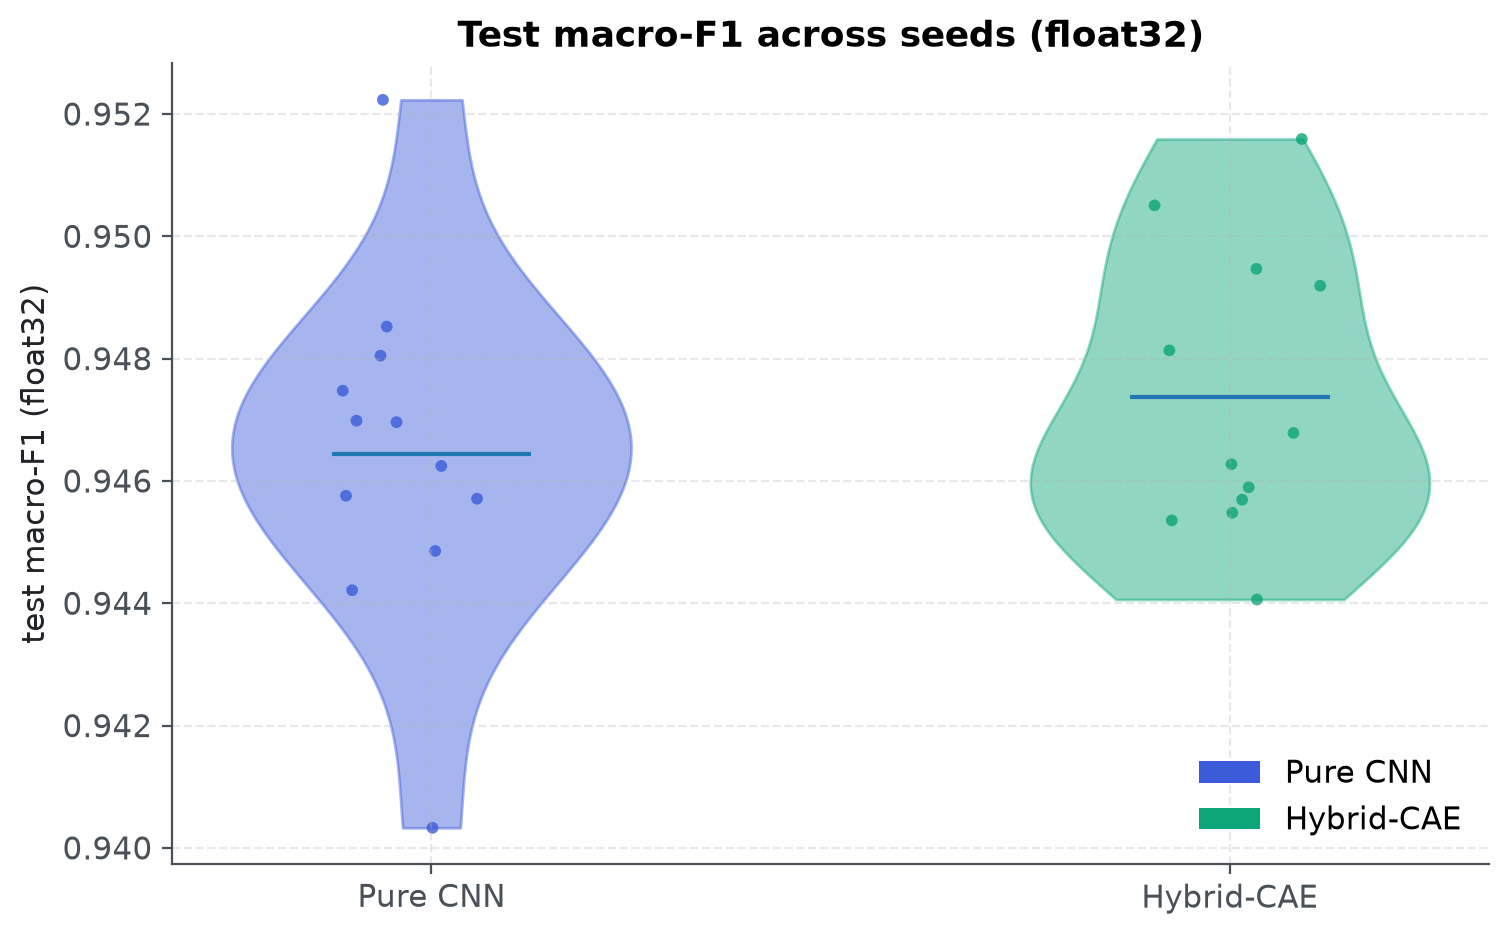

,seed,pure_cnn,hybrid,delta
0,2,0.94805,0.94627,-0.00178
1,7,0.94699,0.94535,-0.00163
2,17,0.94576,0.94569,-0.00007
3,42,0.94852,0.94947,+0.00094
4,55,0.94571,0.94590,+0.00019
5,101,0.94486,0.94406,-0.00079
6,123,0.94421,0.95051,+0.00629
7,313,0.94748,0.94548,-0.00200
8,777,0.94624,0.95159,+0.00535
9,1024,0.95223,0.94678,-0.00545


In [8]:
from eos.utils.visualization import plot_metric_distributions, save_figure

per_seed = {}
for run in bundle["runs"]:
    if run["classification"] is not None:
        per_seed.setdefault(run["mode"], {})[run["seed"]] = run["classification"]["macro_f1"]

seeds = sorted(per_seed["classifier"])
clf_scores = [per_seed["classifier"][seed] for seed in seeds]
hyb_scores = [per_seed["hybrid"][seed] for seed in seeds]
deltas = [hybrid - pure for pure, hybrid in zip(clf_scores, hyb_scores, strict=True)]
replicates = [
    run["classification"]["macro_f1"]
    for run in bundle["runs"]
    if run["mode"] == "hybrid" and run["seed"] == 42 and run["classification"] is not None
]
noise_floor = abs(replicates[0] - replicates[-1])

fig, ax = plot_metric_distributions(
    [clf_scores, hyb_scores],
    arm_names=["Pure CNN", "Hybrid-CAE"],
    metric_name="test macro-F1 (float32)",
    title="Test macro-F1 across seeds (float32)",
)
figure_path = save_figure(fig, FIGURES_DIR / "macro_f1_distributions.png")
display(Image(filename=str(figure_path)))

pd.DataFrame(
    {
        "seed": seeds,
        "pure_cnn": clf_scores,
        "hybrid": hyb_scores,
        "delta": deltas,
    }
).style.format({"pure_cnn": "{:.5f}", "hybrid": "{:.5f}", "delta": "{:+.5f}"})

In [9]:
from scipy import stats

positive = sum(1 for value in deltas if value > 0)
t_two = stats.ttest_rel(hyb_scores, clf_scores)
t_one_sided = t_two.pvalue / 2 if t_two.statistic > 0 else 1 - t_two.pvalue / 2
sign_p = stats.binomtest(positive, len(deltas), 0.5, alternative="greater").pvalue

print(f"seeds per arm          {len(deltas)}")
print(f"mean paired delta      {np.mean(deltas):+.5f}")
print(f"std of paired deltas   {np.std(deltas, ddof=1):.5f}")
print(f"seeds positive         {positive}/{len(deltas)}")
print(
    f"paired t-test          t={t_two.statistic:+.3f}  two-sided p={t_two.pvalue:.4f}"
    f"  one-sided p={t_one_sided:.4f}"
)
print(f"sign test (binomial)   p={sign_p:.4f}")
print(f"run-to-run noise floor {noise_floor:.5f}  (same seed, two trainings, float32)")
print("evaluation regime      float32 (finding F-002)")

seeds per arm          12
mean paired delta      +0.00092
std of paired deltas   0.00387
seeds positive         6/12
paired t-test          t=+0.828  two-sided p=0.4255  one-sided p=0.2128
sign test (binomial)   p=0.6128
run-to-run noise floor 0.00153  (same seed, two trainings, float32)
evaluation regime      float32 (finding F-002)


## Per-class analysis, the decisive slice

An average can move while the mechanism stays hidden. If reconstruction
regularization helps by preserving image detail, the gain should concentrate in
classes that are distinguished by texture rather than by shape, which is exactly the
cropland complex: HerbaceousVegetation, AnnualCrop, PermanentCrop. My original
prediction was different: I expected River versus Highway, a shape-adjacent pair, to
benefit most. It does not.

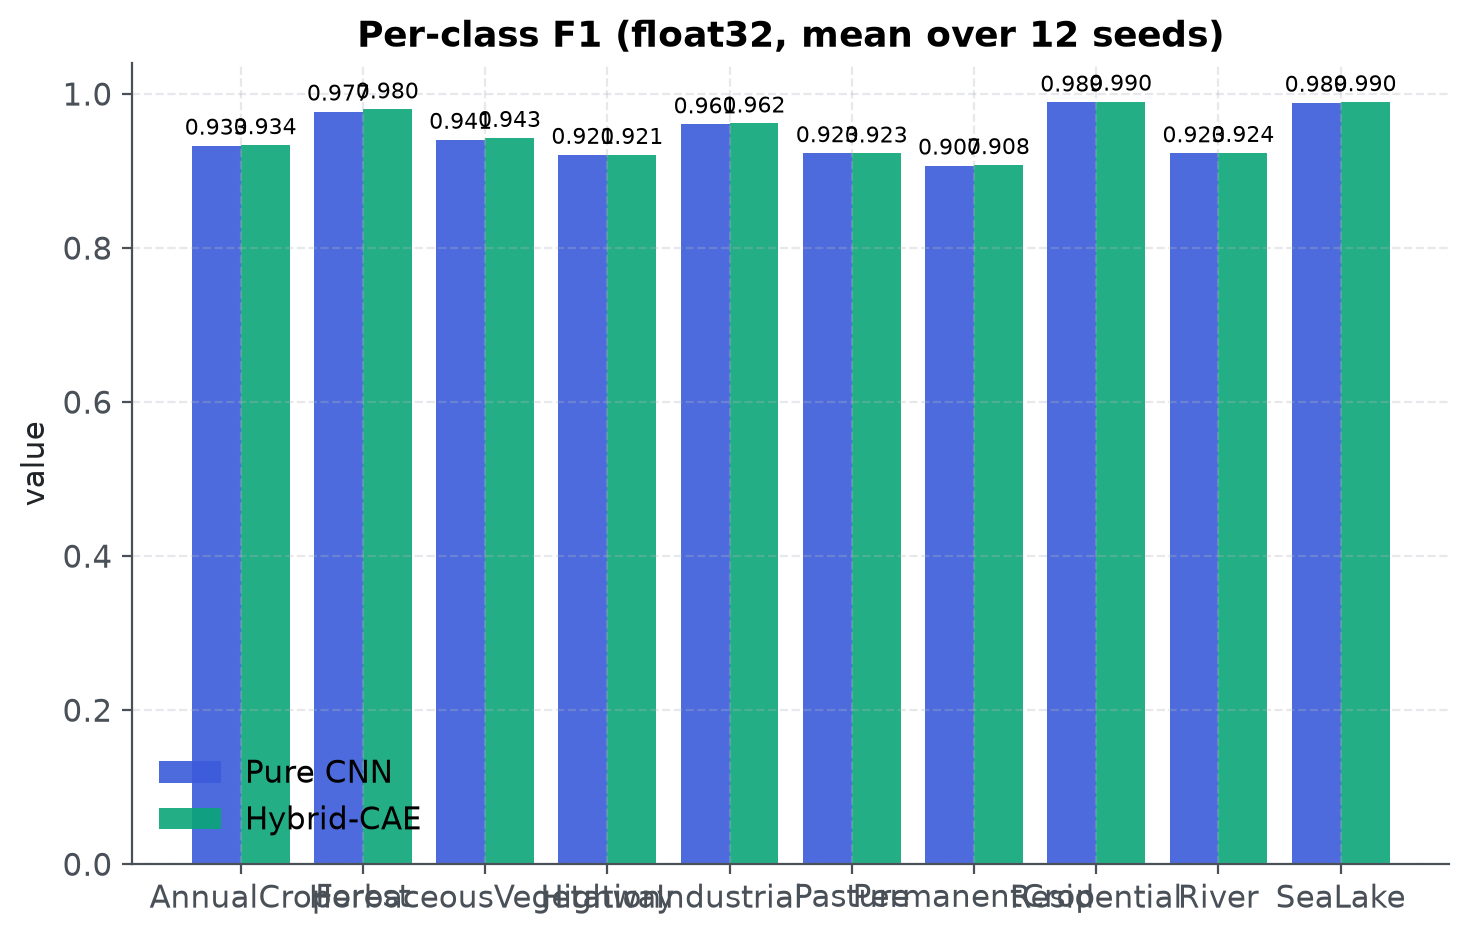

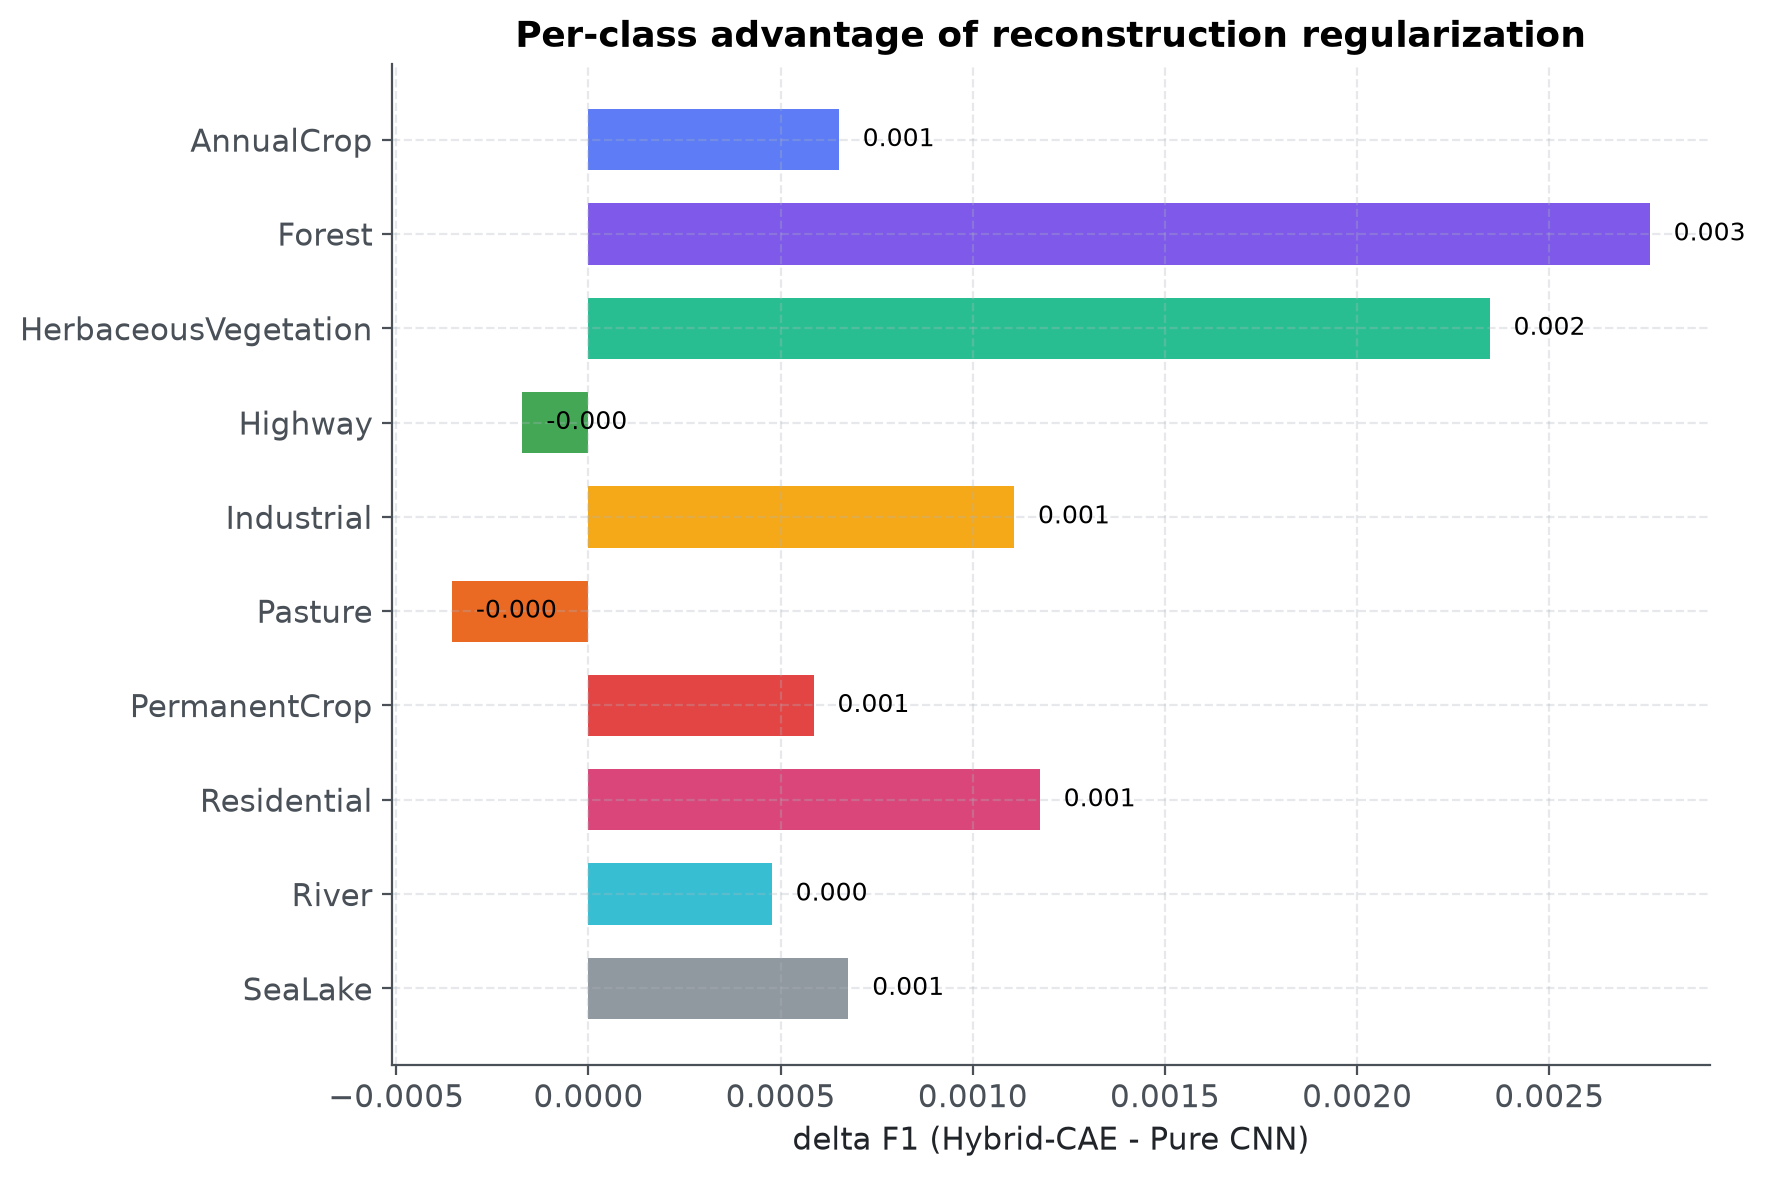

,class,pure_cnn,hybrid,delta
1,Forest,0.9773,0.9801,+0.0028
2,HerbaceousVegetation,0.9407,0.9430,+0.0023
7,Residential,0.9891,0.9902,+0.0012
4,Industrial,0.9607,0.9618,+0.0011
9,SeaLake,0.9888,0.9895,+0.0007
0,AnnualCrop,0.9331,0.9337,+0.0007
6,PermanentCrop,0.9072,0.9078,+0.0006
8,River,0.9231,0.9236,+0.0005
3,Highway,0.9212,0.9210,-0.0002
5,Pasture,0.9233,0.9229,-0.0004


In [10]:
from eos.utils.visualization import plot_ablation_bars, plot_class_metrics_bar

per_class = {}
for run in bundle["runs"]:
    if run["classification"] is not None:
        per_class.setdefault(run["mode"], {})[run["seed"]] = run["classification"]["per_class_f1"]

mean_clf = {
    name: float(np.mean([per_class["classifier"][seed][name] for seed in seeds]))
    for name in class_names
}
mean_hyb = {
    name: float(np.mean([per_class["hybrid"][seed][name] for seed in seeds]))
    for name in class_names
}
delta_values = [mean_hyb[name] - mean_clf[name] for name in class_names]

fig, ax = plot_ablation_bars(
    {"Pure CNN": mean_clf, "Hybrid-CAE": mean_hyb},
    title=f"Per-class F1 (float32, mean over {len(seeds)} seeds)",
)
figure_path = save_figure(fig, FIGURES_DIR / "per_class_f1.png")
display(Image(filename=str(figure_path)))

fig, ax = plot_class_metrics_bar(
    delta_values,
    metric_name="delta F1 (Hybrid-CAE - Pure CNN)",
    class_names=class_names,
    title="Per-class advantage of reconstruction regularization",
)
figure_path = save_figure(fig, FIGURES_DIR / "per_class_delta.png")
display(Image(filename=str(figure_path)))

pd.DataFrame(
    {
        "class": class_names,
        "pure_cnn": [mean_clf[name] for name in class_names],
        "hybrid": [mean_hyb[name] for name in class_names],
        "delta": delta_values,
    }
).sort_values("delta", ascending=False).style.format(
    {"pure_cnn": "{:.4f}", "hybrid": "{:.4f}", "delta": "{:+.4f}"}
)

## Confusion matrices

Rows are true classes, columns are predictions, normalized per row. Both models
confuse the same pairs, which is what you would expect from near-identical
encoders. The block to look at is AnnualCrop against PermanentCrop: two cropland
classes that differ mostly in texture. This is where the per-class gains live.

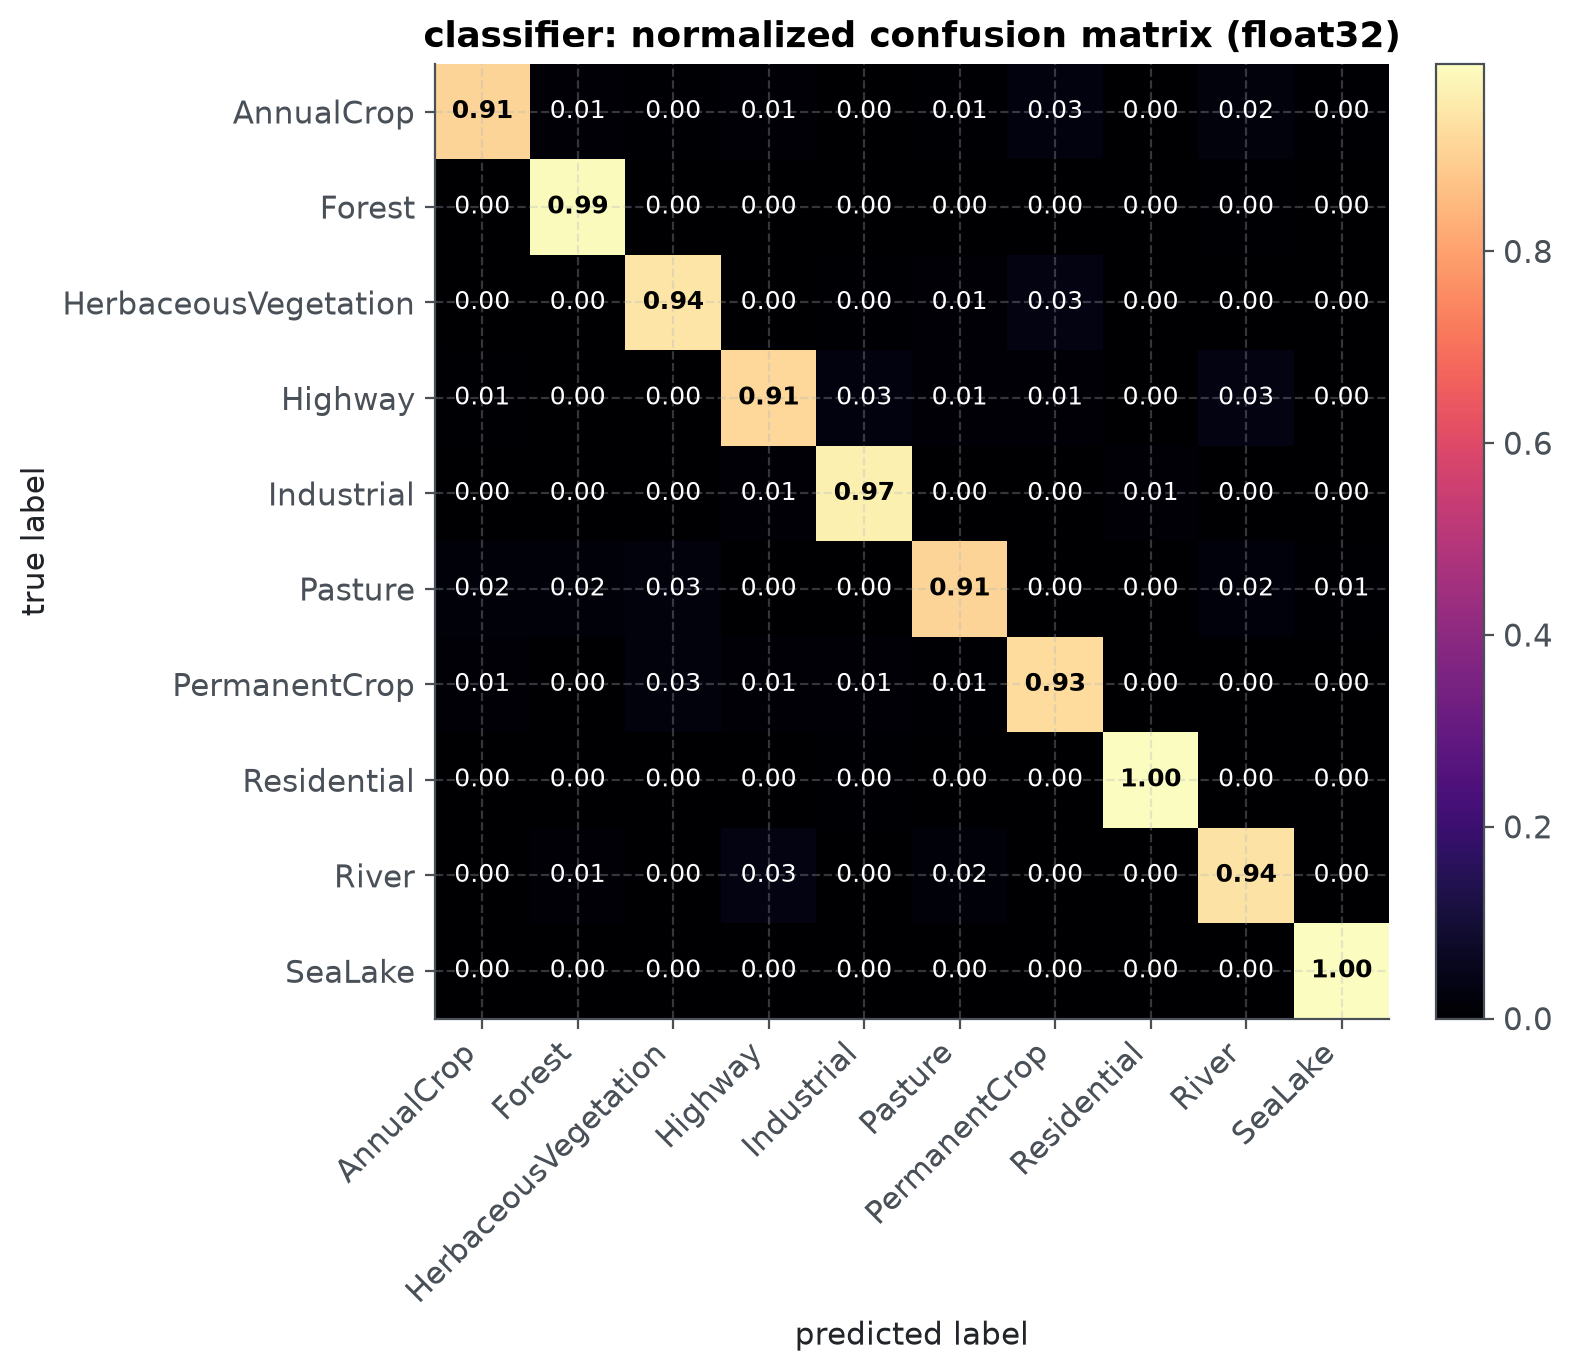

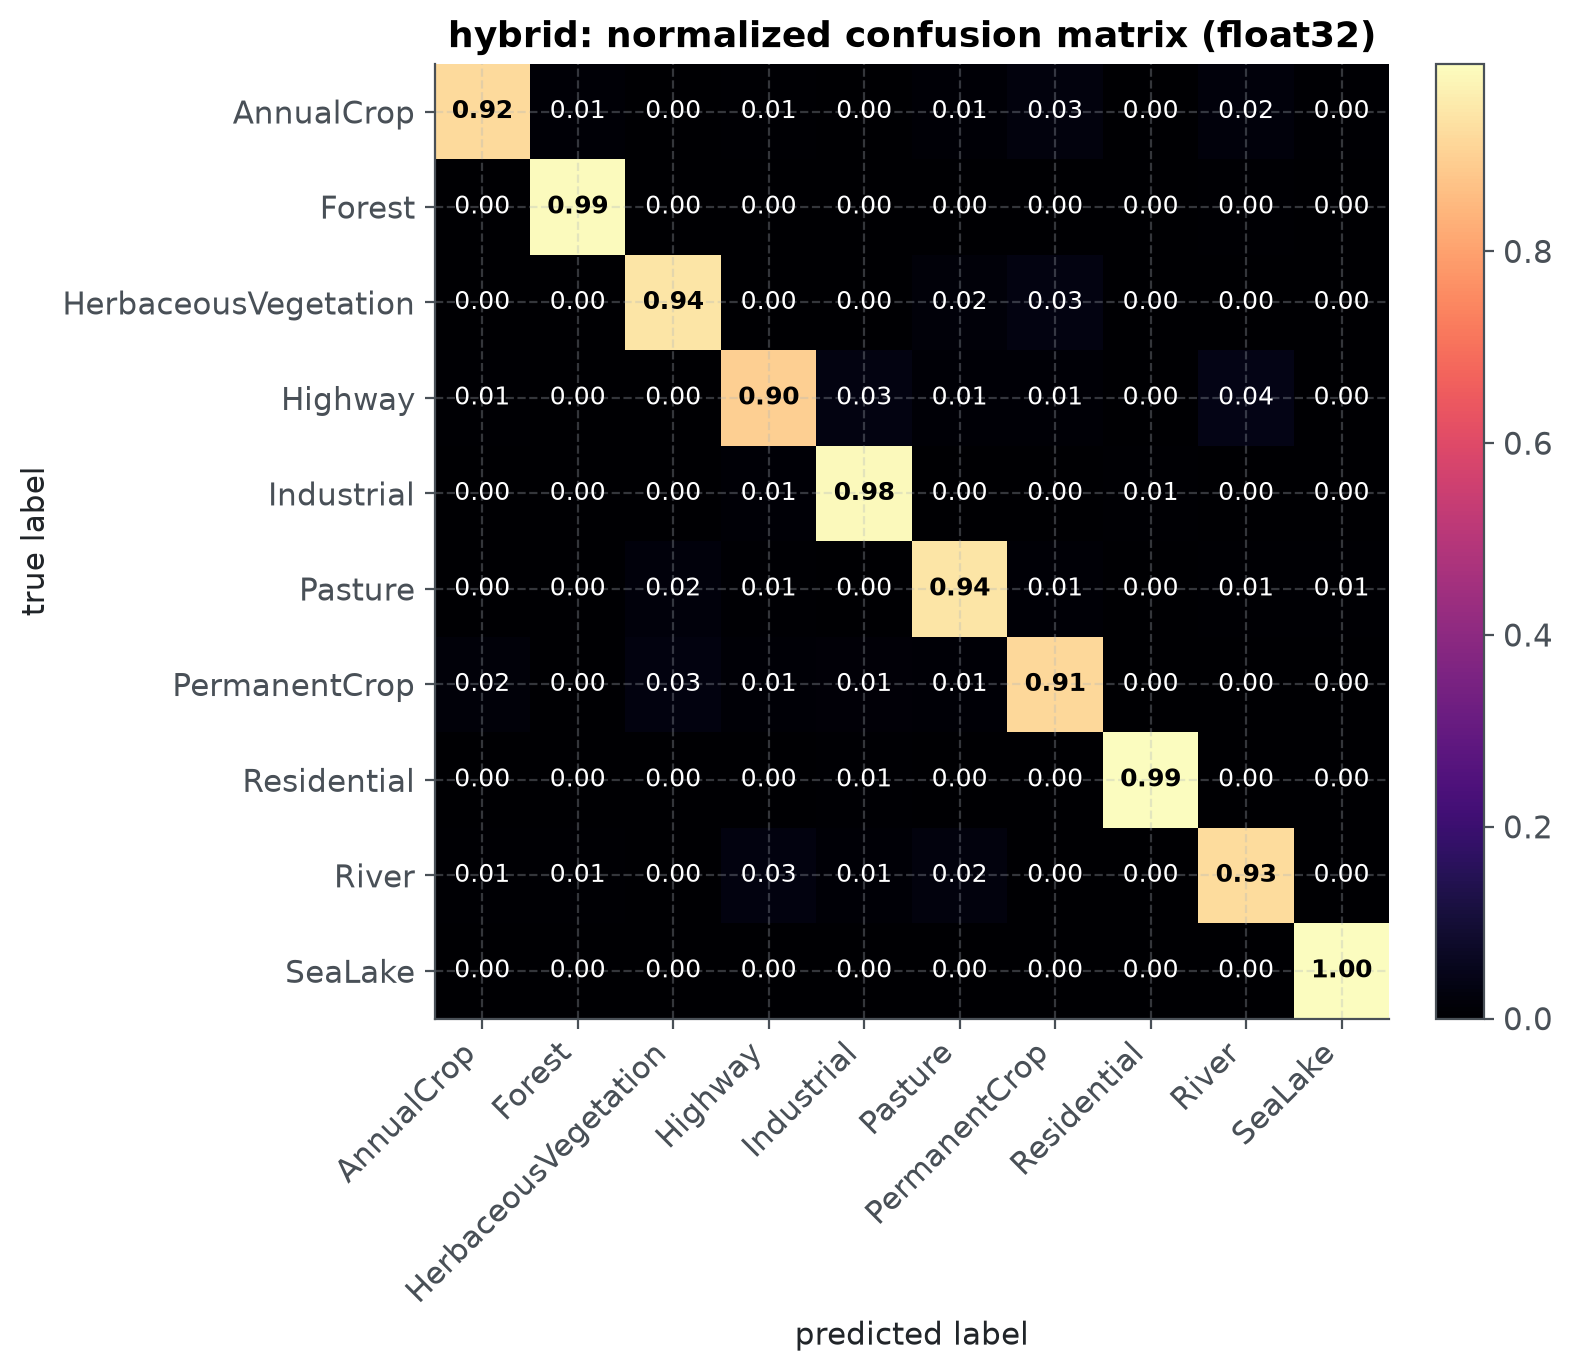

In [11]:
from eos.utils.visualization import plot_confusion_matrix

for mode in ("classifier", "hybrid"):
    run = max(
        (r for r in bundle["runs"] if r["mode"] == mode and r["seed"] == 42),
        key=lambda r: r["run_name"],
    )
    matrix = np.array(run["classification"]["confusion"], dtype=np.int64)
    fig, ax = plot_confusion_matrix(
        matrix,
        class_names=class_names,
        normalize=True,
        title=f"{mode}: normalized confusion matrix (float32)",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"confusion_{mode}.png")
    display(Image(filename=str(figure_path)))

## Reconstruction grids and residual heatmaps

Each row pairs an input patch with the decoder's redraw of it. The autoencoder arm
sets the reconstruction ceiling; the hybrid pays part of that ceiling for
classification accuracy.

The first thing you notice is that the reconstructions are visibly softer and
flatter than the originals. That is not a bug in this pipeline, it is what this
architecture and loss can produce; the conclusion section works through exactly
why, and what the decoder is still good for despite it.

The residual maps show $|X - \hat{X}|$, per pixel. Bright regions are the
structures the bottleneck discarded: fine texture, small objects, sharp boundaries.
Those maps are the interesting output of a reconstruction head, because they point
at what the model finds hard, pixel by pixel.

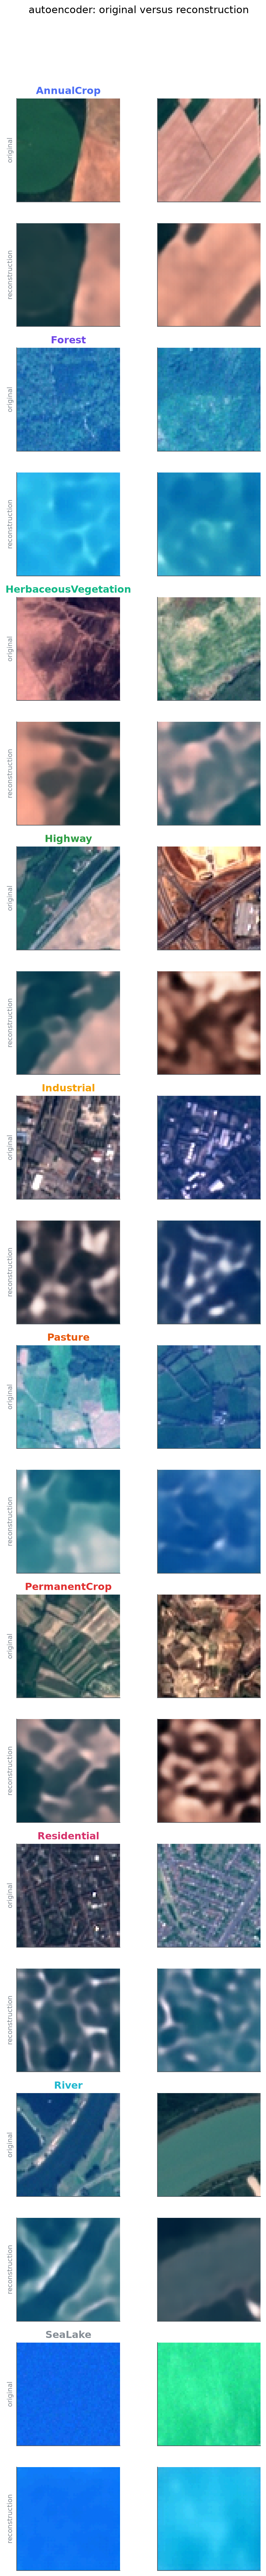

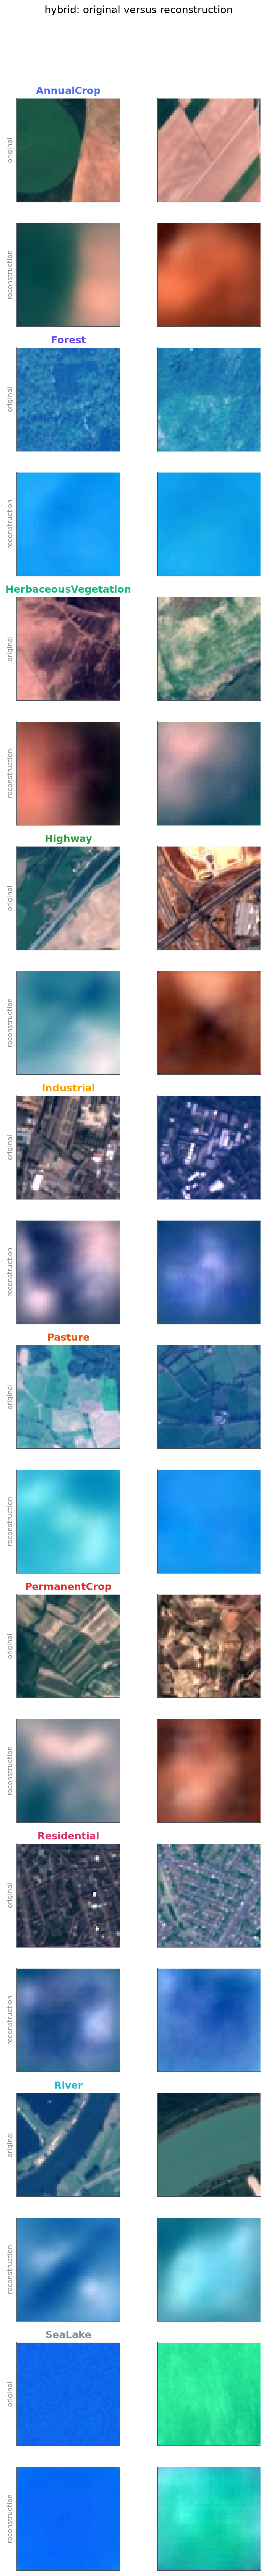

In [12]:
from eos.utils.visualization import plot_patch_grid, plot_residual_heatmaps

samples = {
    mode: np.load(EVIDENCE_DIR / f"recon_samples_{mode}.npz") for mode in ("autoencoder", "hybrid")
}

for mode, data in samples.items():
    fig, axes = plot_patch_grid(
        data["originals"],
        data["reconstructions"],
        data["labels"],
        class_names=class_names,
        max_per_class=2,
        title=f"{mode}: original versus reconstruction",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"patch_grid_{mode}.png")
    display(Image(filename=str(figure_path)))

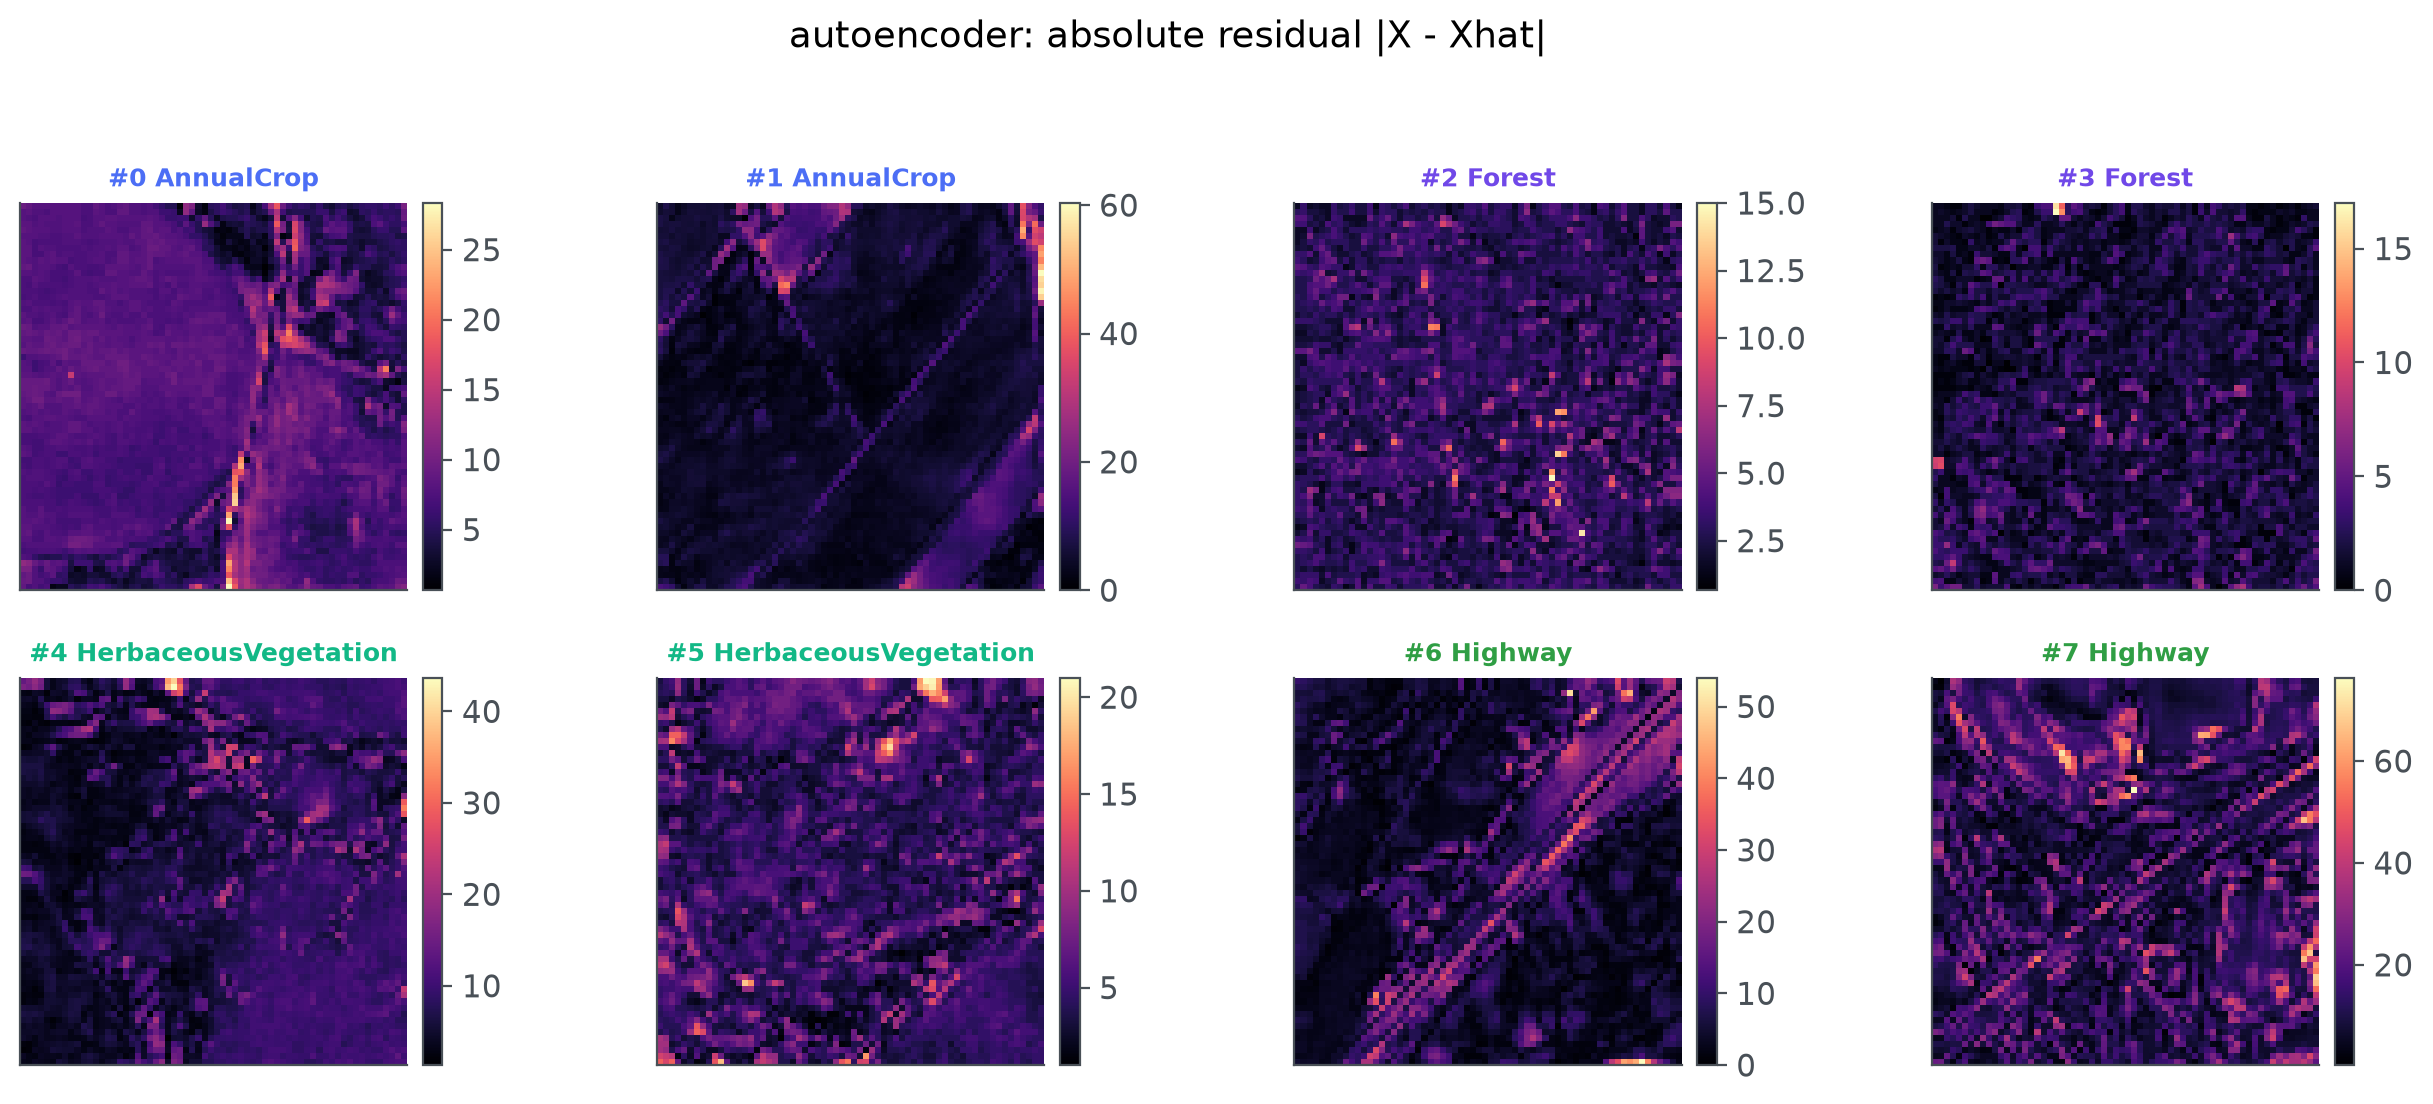

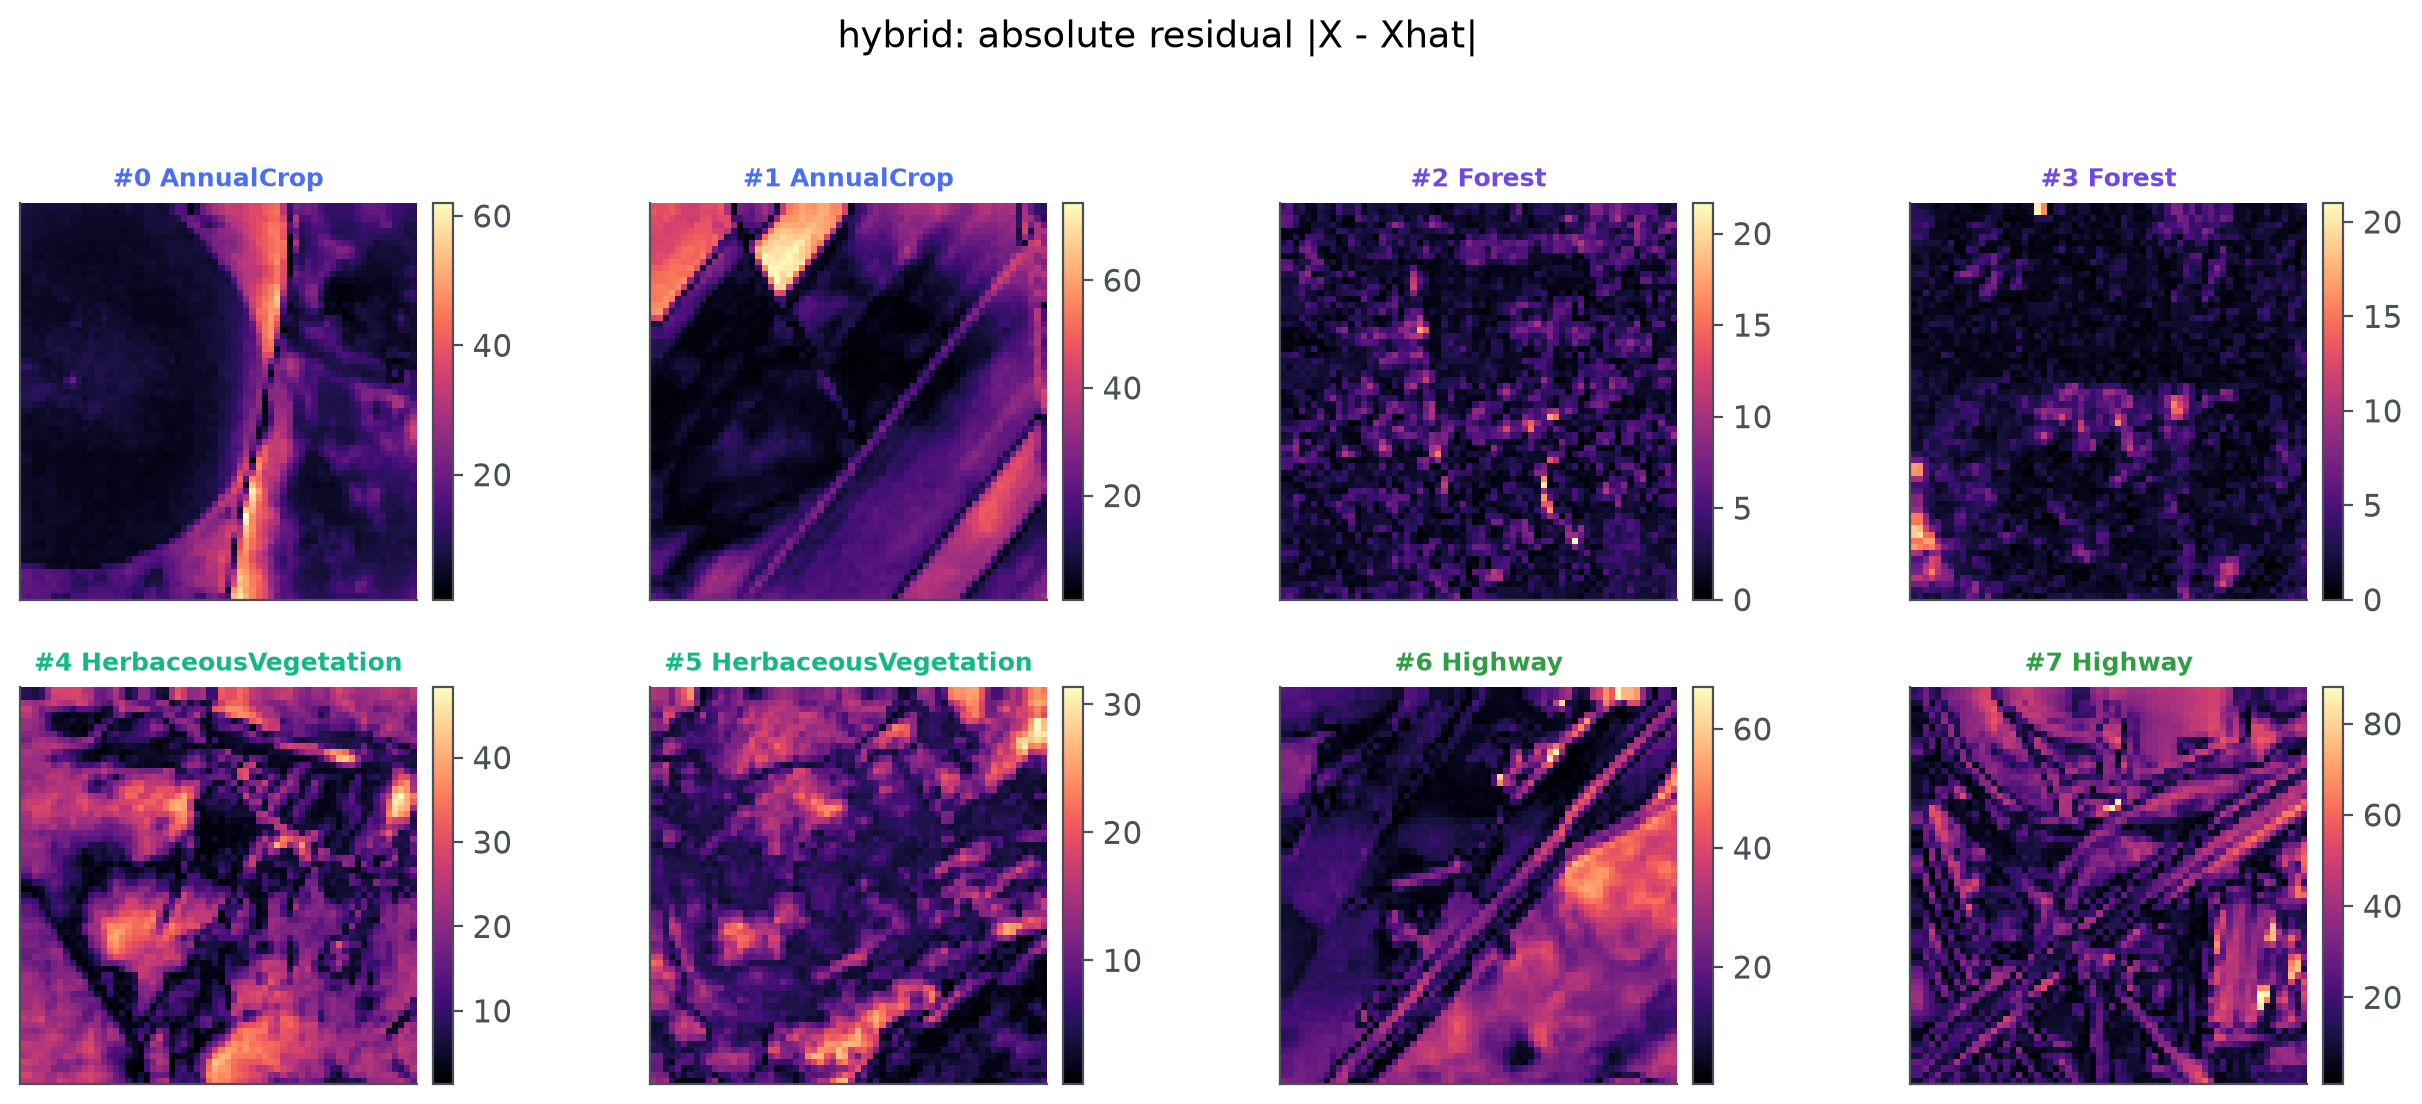

In [13]:
for mode, data in samples.items():
    fig, axes = plot_residual_heatmaps(
        data["originals"],
        data["reconstructions"],
        data["labels"],
        class_names=class_names,
        max_samples=8,
        title=f"{mode}: absolute residual |X - Xhat|",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"residuals_{mode}.png")
    display(Image(filename=str(figure_path)))

## Latent manifold projections

Each point is one test patch pushed through the encoder, reduced from 128 numbers
to 2 so it can be drawn. PCA keeps the directions of greatest variance, so its
distances are honest. t-SNE keeps local neighborhoods, so clusters that touch are
meaningful but distances between clusters are not: t-SNE will happily push two
genuine clusters far apart. Read these pictures as "which classes share a
neighborhood", never as a map.

The comparison that matters is the Pure CNN encoder against the Hybrid-CAE
encoder: if reconstruction regularization changes what the bottleneck keeps, it
shows up as tighter or better-separated cropland clusters.

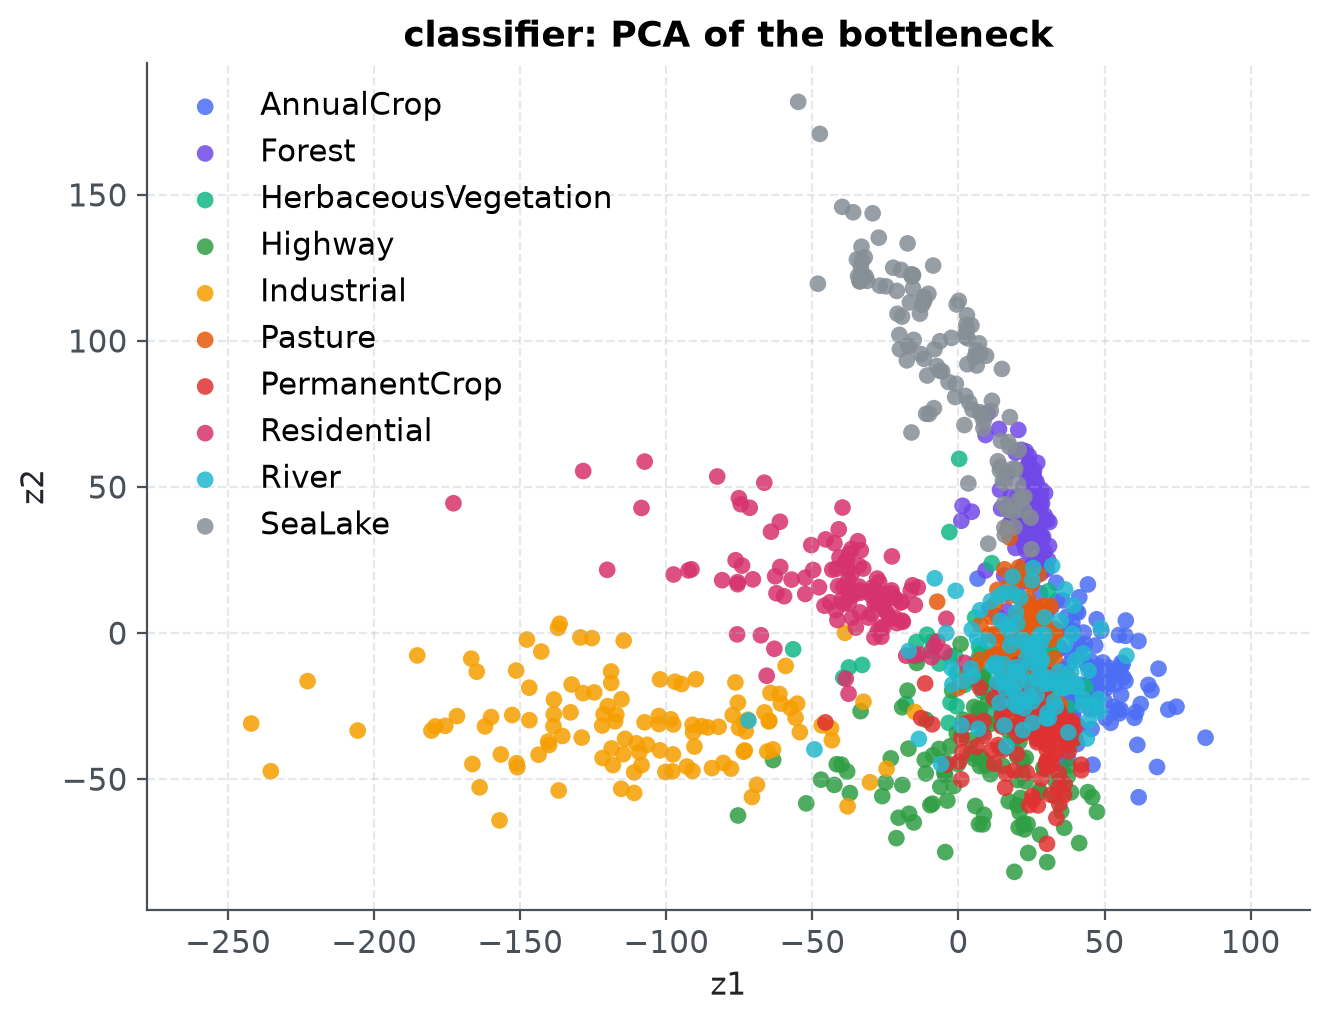

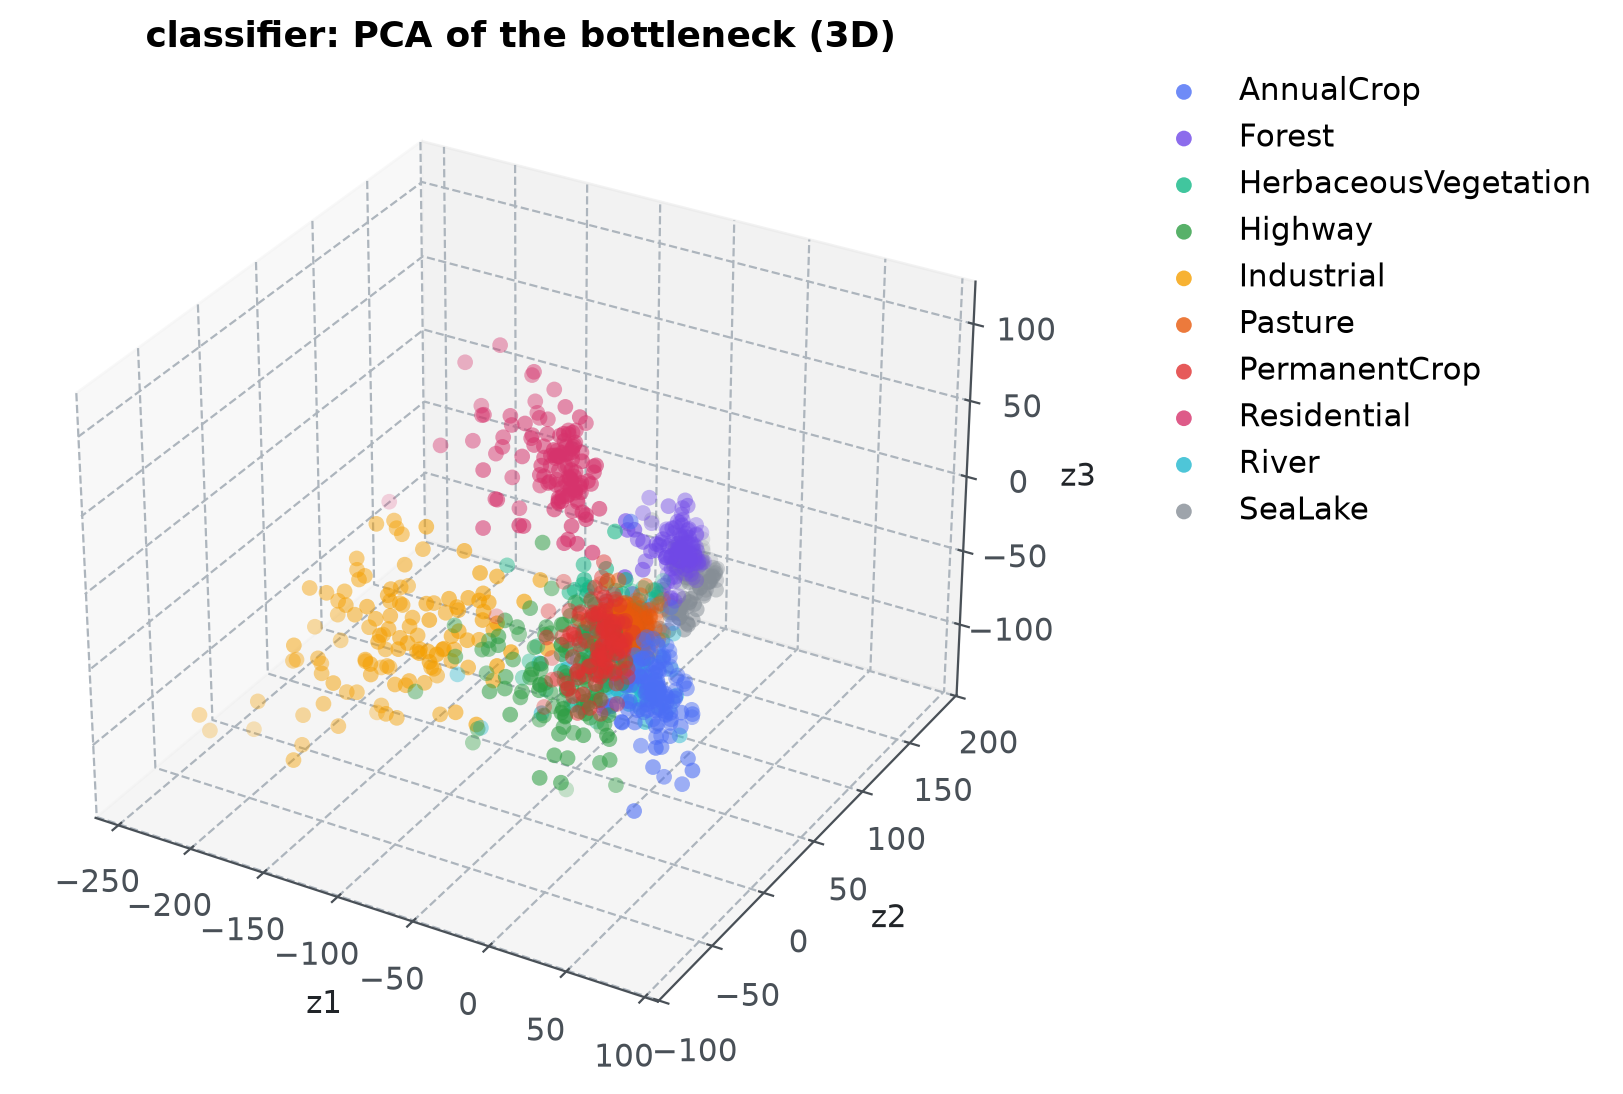

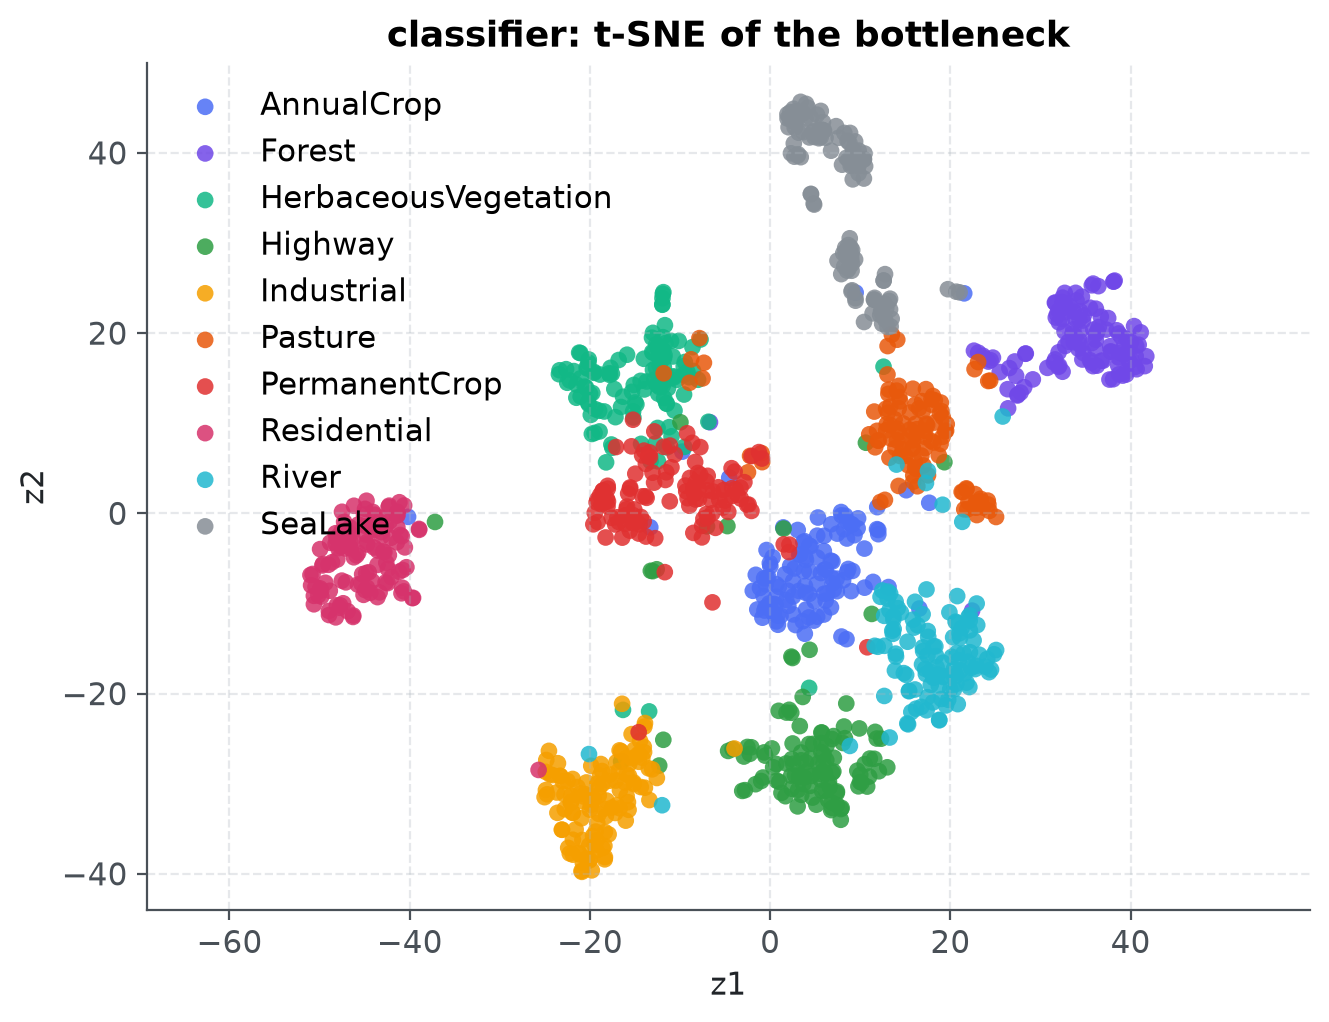

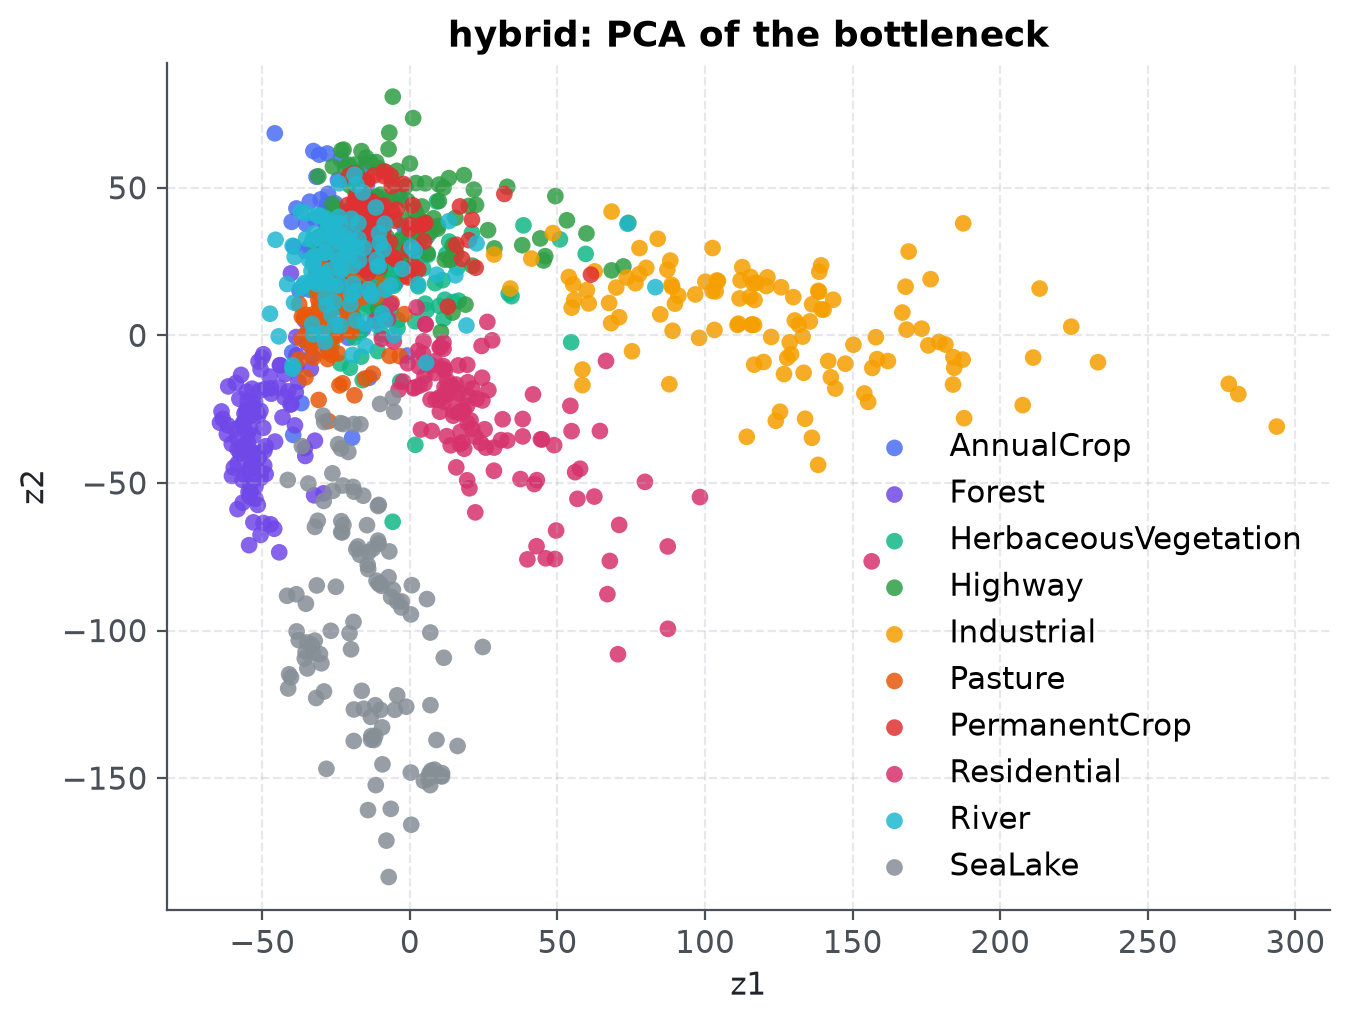

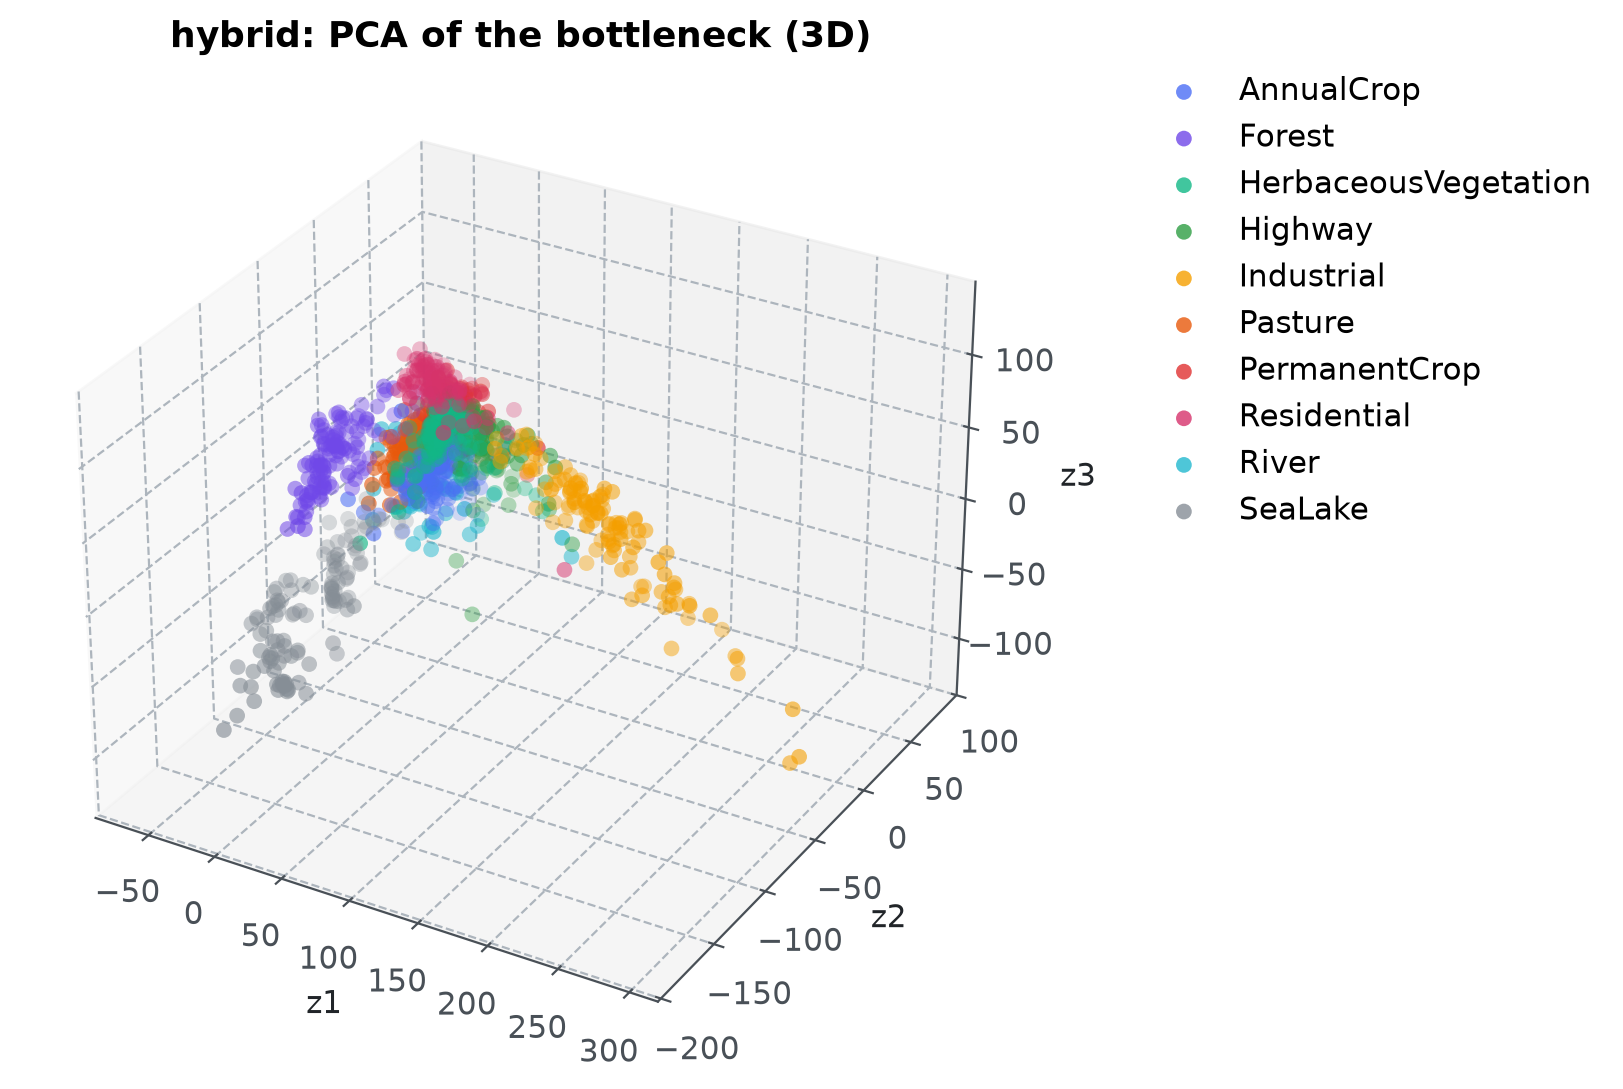

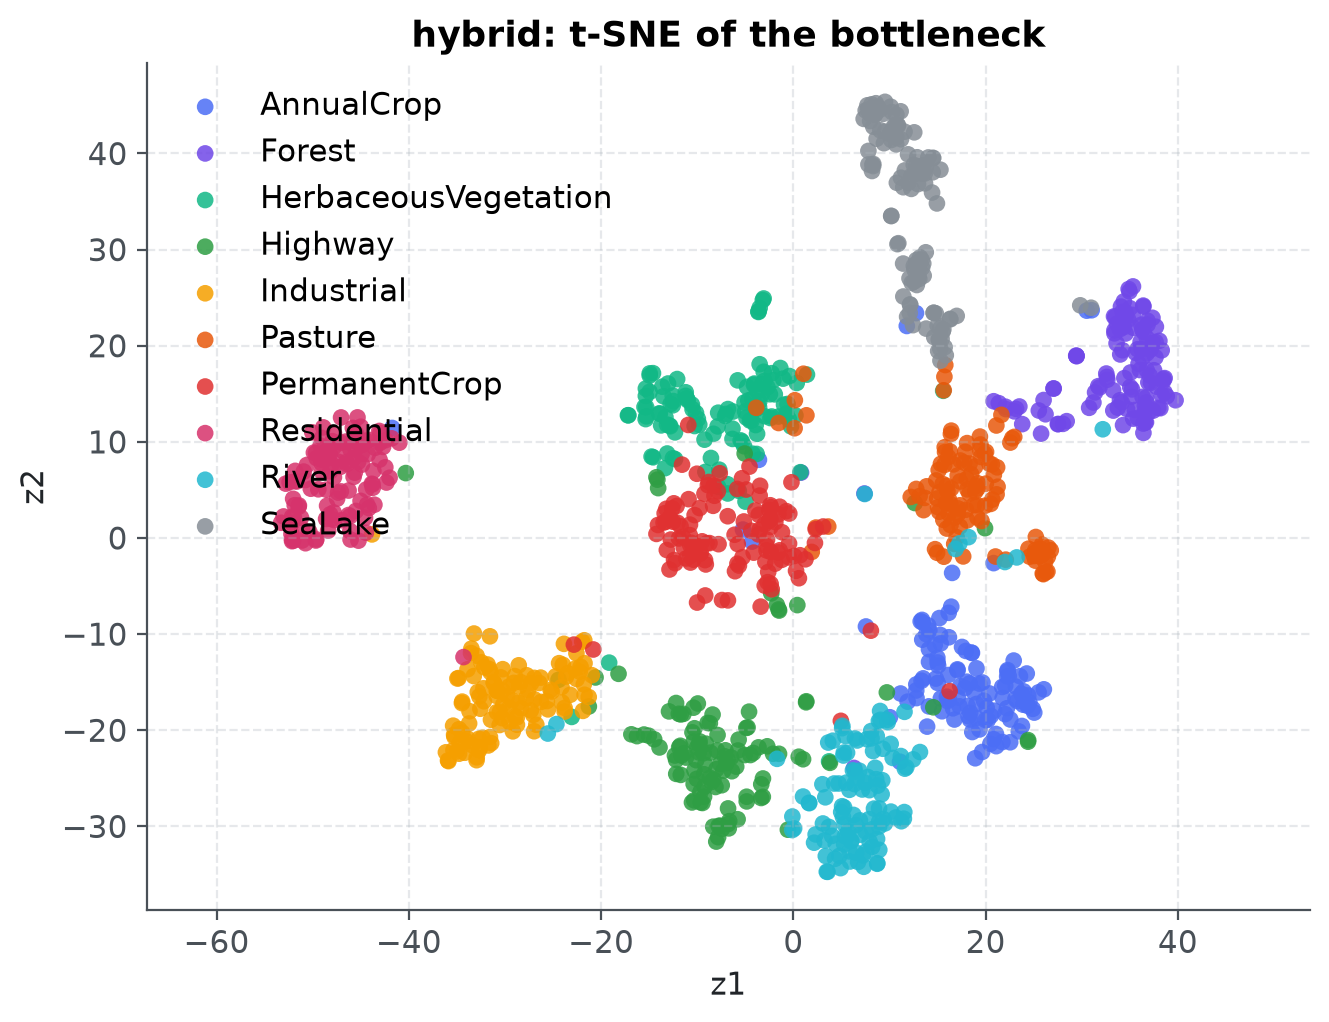

In [14]:
from sklearn.manifold import TSNE

from eos.utils.visualization import (
    plot_histogram_3d,
    plot_latent_projection,
    plot_latent_scatter_3d,
)

embeddings = {
    mode: np.load(EVIDENCE_DIR / f"embeddings_{mode}.npz") for mode in ("classifier", "hybrid")
}

for mode, data in embeddings.items():
    z = data["embeddings"]
    labels = data["labels"]
    centered = z - z.mean(axis=0)
    _, _, components = np.linalg.svd(centered, full_matrices=False)
    pca_2d = centered @ components[:2].T
    pca_3d = centered @ components[:3].T
    fig, ax = plot_latent_projection(
        pca_2d, labels, class_names=class_names, title=f"{mode}: PCA of the bottleneck"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_pca2d_{mode}.png")
    display(Image(filename=str(figure_path)))

    fig, ax = plot_latent_scatter_3d(
        pca_3d, labels, class_names=class_names, title=f"{mode}: PCA of the bottleneck (3D)"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_pca3d_{mode}.png")
    display(Image(filename=str(figure_path)))

    tsne_2d = TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(z)
    fig, ax = plot_latent_projection(
        tsne_2d, labels, class_names=class_names, title=f"{mode}: t-SNE of the bottleneck"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_tsne_{mode}.png")
    display(Image(filename=str(figure_path)))

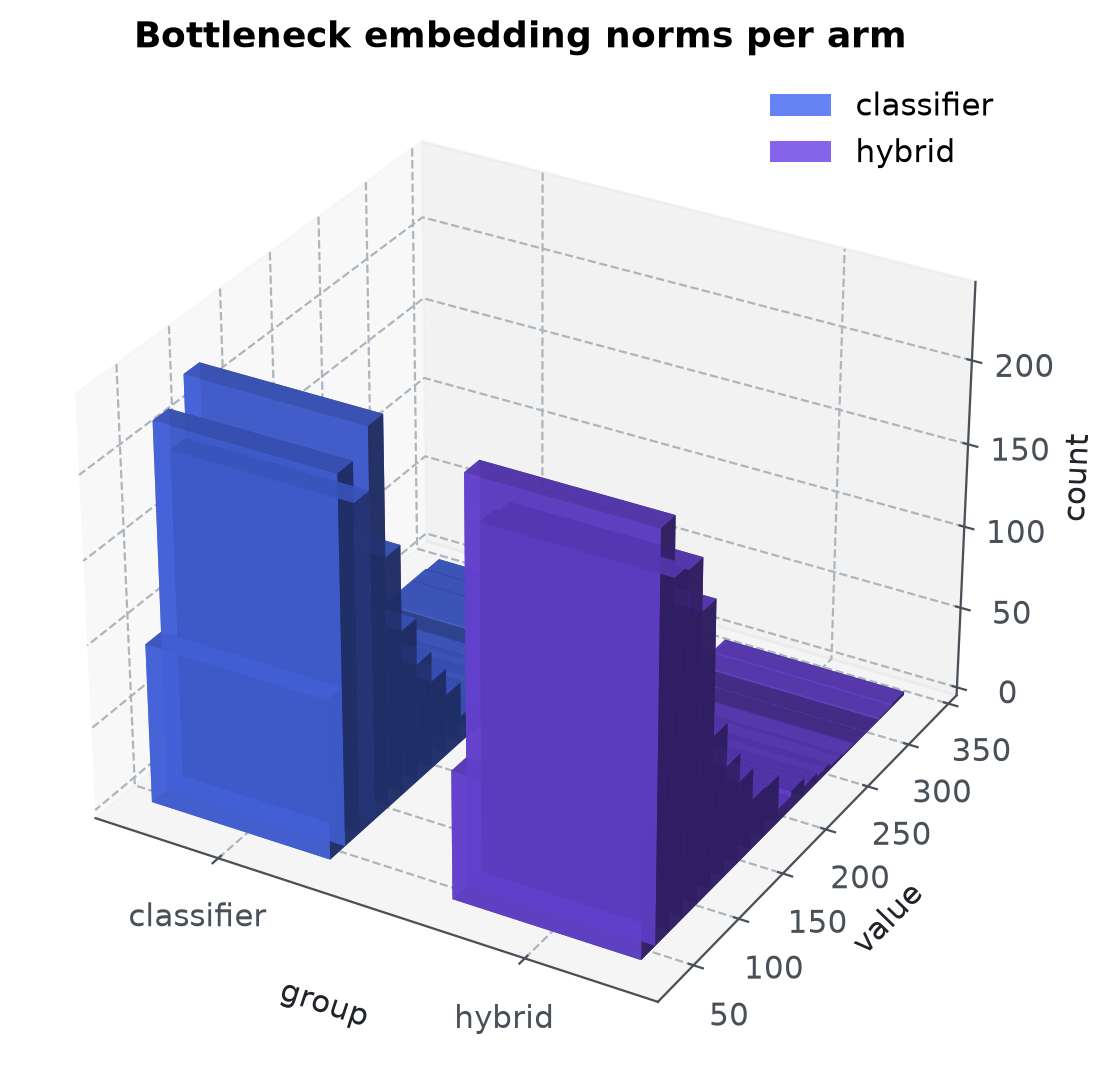

In [15]:
norms = [np.linalg.norm(data["embeddings"], axis=1) for data in embeddings.values()]

fig, ax = plot_histogram_3d(
    norms,
    group_names=list(embeddings),
    bins=20,
    title="Bottleneck embedding norms per arm",
)
figure_path = save_figure(fig, FIGURES_DIR / "embedding_norms_3d.png")
display(Image(filename=str(figure_path)))

## Loss trajectories

Per-epoch curves as recorded during the full-budget runs. The classification loss
falls fast and plateaus; the reconstruction term improves slowly and keeps drifting
down long after the classifier has stopped, which is one reason the decoder is
chronically undertrained relative to the head it shares an encoder with.

The hybrid optimizes $\mathrm{CE} + \lambda(t)\,(0.85\,\mathrm{MSE} +
0.15\,(1-\mathrm{SSIM}))$ with $\lambda(t)$ annealed from 0.3 down to 0.1. The
schedule matters: reconstruction starts as a real training signal and fades into a
gentle constraint, so the bottleneck keeps spatial detail without being forced to
spend its capacity on pixel-perfect redraws.

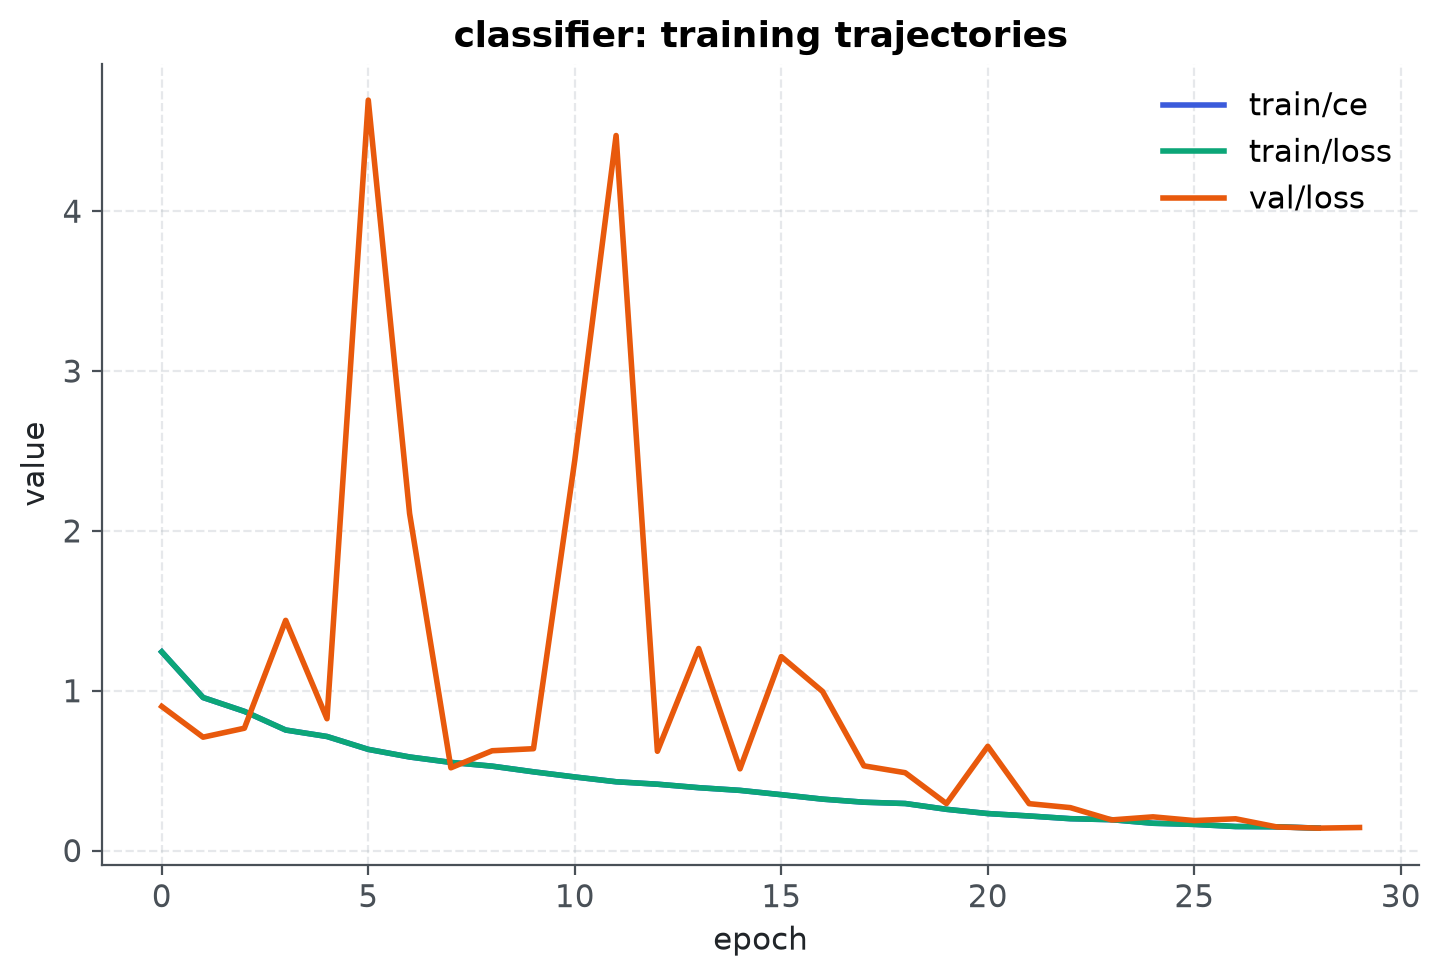

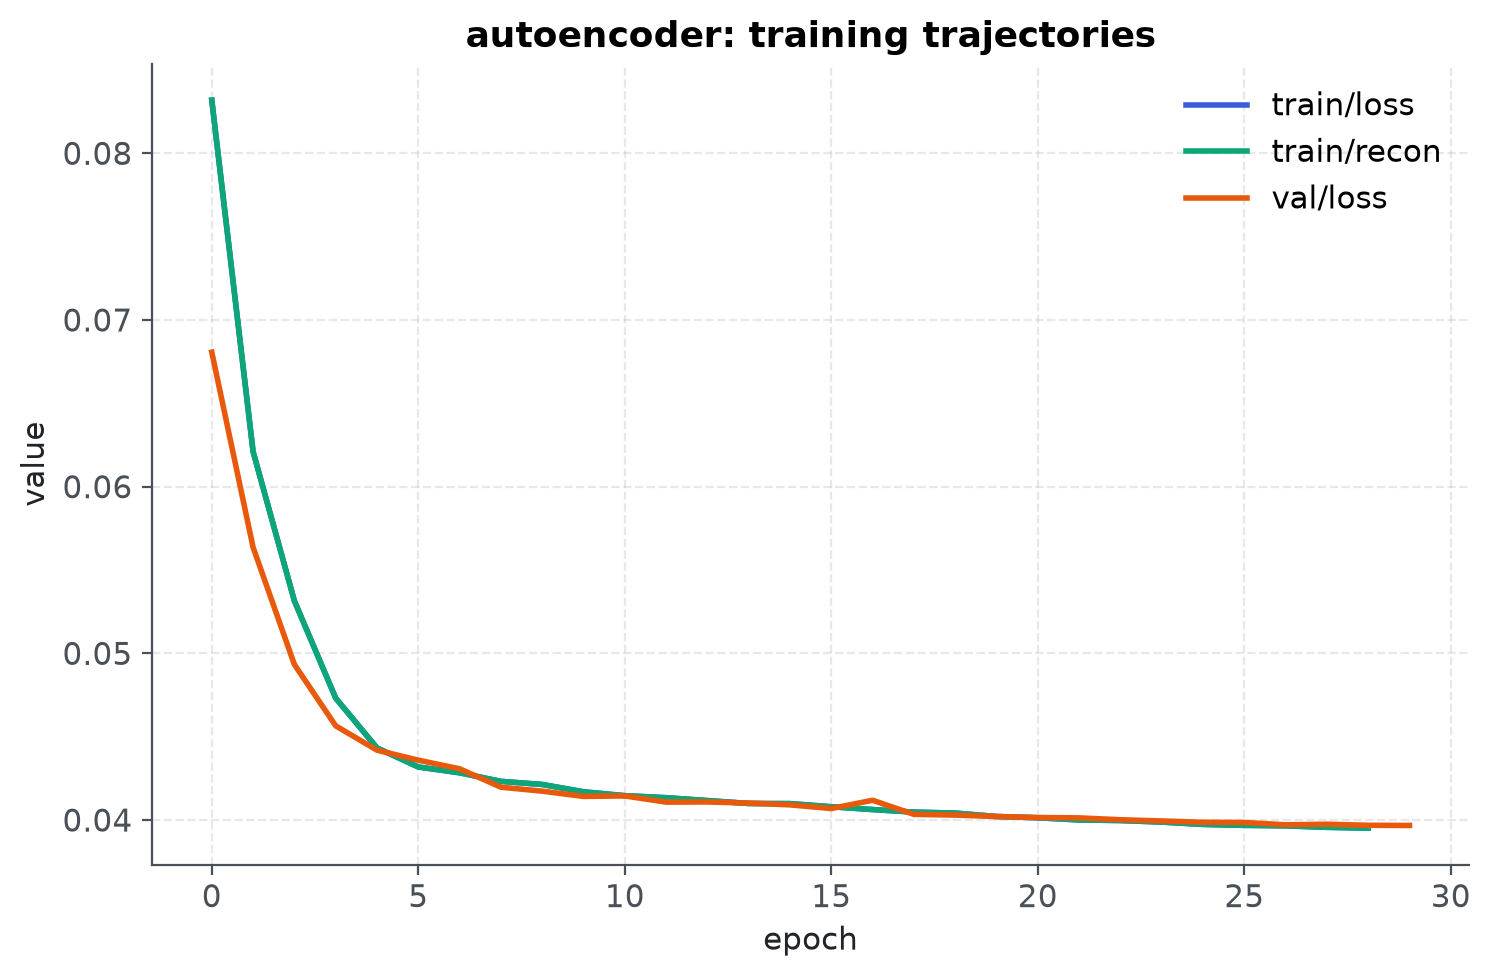

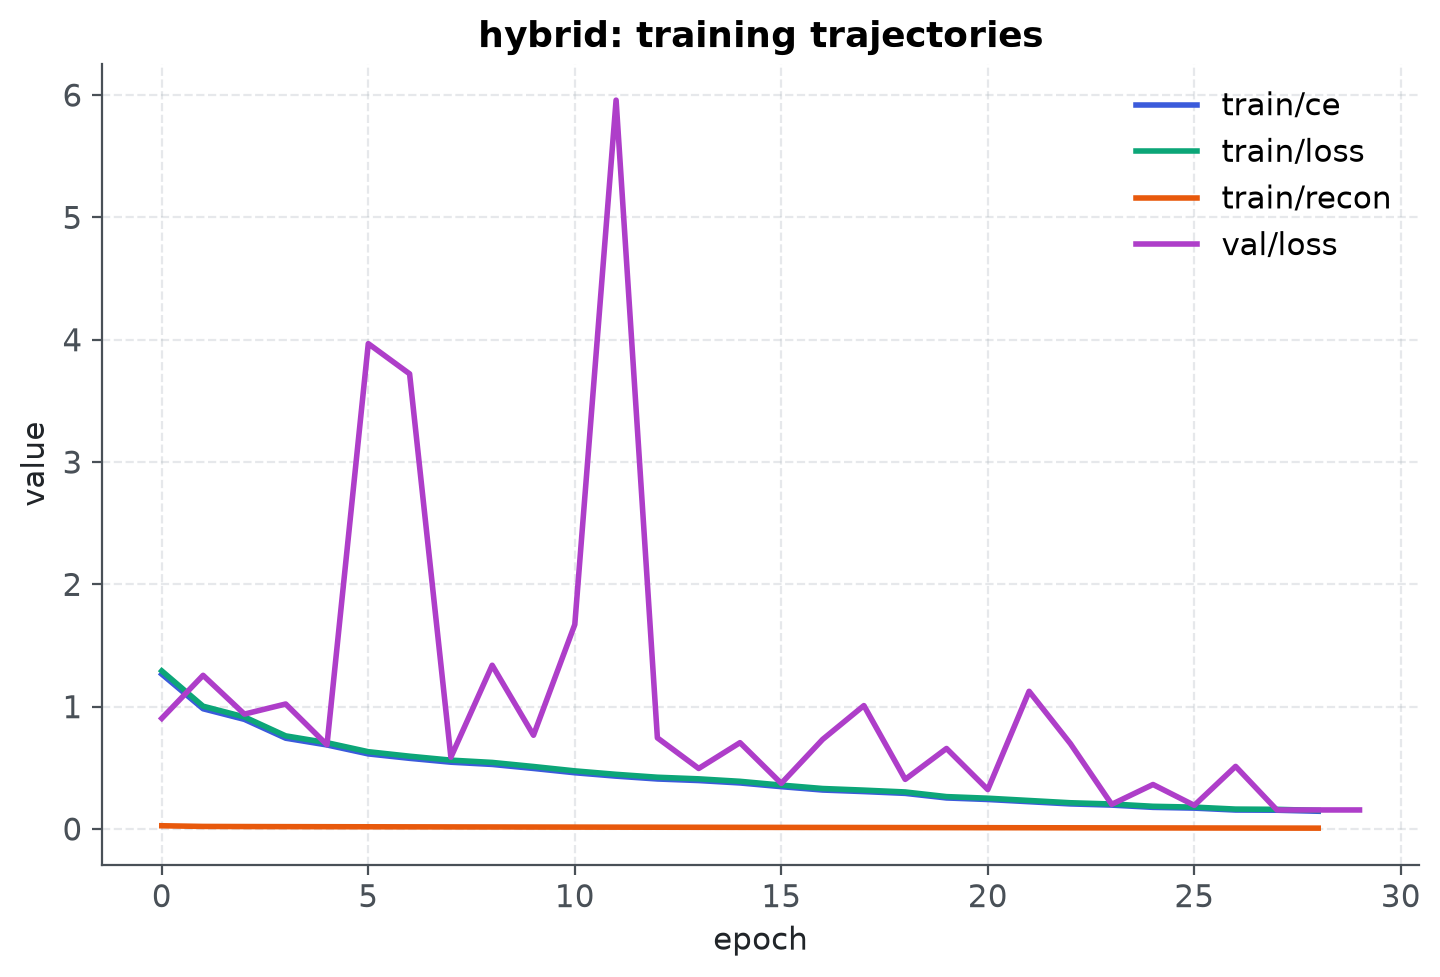

In [16]:
from eos.utils.visualization import plot_loss_trajectories

for mode in ("classifier", "autoencoder", "hybrid"):
    run = max(
        (r for r in bundle["runs"] if r["mode"] == mode and r["seed"] == 42),
        key=lambda r: r["run_name"],
    )
    history = {
        key: values
        for key, values in run["history"].items()
        if key in ("train/loss", "train/ce", "train/recon", "val/loss")
    }
    fig, ax = plot_loss_trajectories(history, title=f"{mode}: training trajectories")
    figure_path = save_figure(fig, FIGURES_DIR / f"loss_trajectories_{mode}.png")
    display(Image(filename=str(figure_path)))

## ASVD compression

Trained layers are larger than they need to be. For a weight matrix
$W \in \mathbb{R}^{m \times n}$, the singular value decomposition $W = U \Sigma
V^{\top}$ orders its directions by how much of the matrix they carry. Keeping the
smallest number of directions $k$ whose cumulative energy reaches a target $E$
replaces $m \cdot n$ weights with $k \cdot (m + n)$. The gain guard only accepts a
factorization when $m n / (k(m+n)) \geq 1.1$, so layers that would barely shrink
are left dense and recorded as skipped. The final 10-class projection is never
factorized: its logits are calibrated and truncation would move them.

Two facts frame the result honestly. The hidden classification projection is tiny
(8,256 weights), so the headline compression comes from the bottleneck projections
around $z$. And compression is reported twice: over the dense layers that were
factorized, and over the whole model, because only the second number is what a
deployment feels.

In [17]:
from dataclasses import asdict

from eos.model.compression import factorize_module, state_signature

fresh = build_model("hybrid", config.model)
dense_before = fresh.parameter_count()
result = factorize_module(fresh, config.asvd)
dense_after = fresh.parameter_count()

print(f"state signature {state_signature(result)[:16]}")
print(f"total parameters before/after: {dense_before['total']:,} -> {dense_after['total']:,}")
pd.DataFrame([asdict(layer) for layer in result.layers])

state signature decoder.projecti
total parameters before/after: 6,453,421 -> 6,453,421


,name,shape,rank,energy,params_before,params_after,skipped,reason
0,decoder.projection,"(8192, 128)",120,0.950500,1056768,1056768,True,compression gain 1.050 below the 1.100 floor a...
1,encoder.projection,"(128, 8192)",120,0.950182,1048704,1048704,True,compression gain 1.050 below the 1.100 floor a...


In [18]:
m4_rows = []
for variant in asvd_report["benchmarks"]:
    for entry in variant["scopes"]:
        m4_rows.append(
            {
                "arm": variant["mode"],
                "scope": entry["scope"],
                "energy": entry["preserve_energy"],
                "dense reduction": f"{entry['dense_reduction']:.1%}",
                "model reduction": f"{entry['model_reduction']:.1%}",
                "macro-F1 delta": entry["macro_f1_delta"],
                "M4 passes": entry["m4_passes"],
                "median ms": round(entry["latency"]["median_ms"], 1),
            }
        )
pd.DataFrame(m4_rows)

,arm,scope,energy,dense reduction,model reduction,macro-F1 delta,M4 passes,median ms
0,hybrid,classifier,0.90,0.0%,0.0%,0.000000,False,82.0
1,hybrid,classifier,0.95,0.0%,0.0%,0.000000,False,62.8
2,hybrid,bottleneck,0.90,39.1%,12.8%,0.000209,True,85.6
3,hybrid,bottleneck,0.95,18.2%,5.9%,0.000000,False,77.3
4,hybrid,all_intermediate,0.90,39.0%,12.8%,0.000209,True,85.8
5,hybrid,all_intermediate,0.95,18.1%,5.9%,0.000000,False,83.8
6,classifier,classifier,0.90,0.0%,0.0%,0.000000,False,63.6
7,classifier,classifier,0.95,0.0%,0.0%,0.000000,False,62.0
8,classifier,bottleneck,0.90,62.7%,25.2%,0.000240,True,72.9
9,classifier,bottleneck,0.95,36.5%,14.7%,0.000272,True,57.1


**Reading the table.** The milestone bar is a 30% dense-parameter reduction for
less than 1.5% macro-F1 loss. The hybrid arm clears it at energy 0.90 on the
bottleneck projections: 39% of the dense weights gone for a +0.0002 macro-F1
change, which is zero within the noise budget. At energy 0.95 the gain guard skips
the decoder projection and the reduction falls to 18%, below the bar. The
classifier-only scope is the negative control: its one hidden layer is
gain-guard-skipped at every energy, so nothing compresses and nothing changes.

**On latency.** Factorized layers trade memory for two smaller matmuls instead of
one big one. Measured on CPU and GPU alike, the wall-clock differences sit inside
the run-to-run noise: a variant that compresses nothing at all once benchmarked
30% faster than its own identical baseline. The honest statement is memory
reduction, not acceleration. Every run here also enforces a 12 GiB VRAM budget per
process so the card stays responsive.

## MMD latent-drift telemetry

Once a model is deployed, the world can drift away from the data it was trained on.
I watch for that in the bottleneck itself: for a batch of embeddings, the Maximum
Mean Discrepancy measures how far its mean feature map in a reproducing kernel
Hilbert space sits from the reference distribution's. Two batches from the same
world score near zero; a shifted batch scores high.

Three implementation choices make the threshold trustworthy. The estimator is the
unbiased U-statistic with diagonal terms removed; the biased version systematically
overestimates and would fire constantly. Kernel bandwidths come from the median
pairwise distance scaled by $\{0.25, 0.5, 1, 2, 4\}$, so the test is sensitive at
several scales at once. And the null distribution is bootstrapped at the live batch
size (128), so the alarm threshold $\mu + 3\sigma$ is calibrated for exactly the
sample size it will be used at.

One more guard matters operationally: any ASVD pass rewrites what $z$ means, so the
baseline's fingerprint binds the checkpoint, the factorization state, and the data
manifest. A monitor handed a baseline from a different model state refuses to run.

In [19]:
from eos.telemetry.mmd import calibrate_baseline
from eos.telemetry.mmd_drift import DriftMonitor

all_z = torch.from_numpy(embeddings["hybrid"]["embeddings"]).float()
all_y = embeddings["hybrid"]["labels"]
order = torch.randperm(len(all_z), generator=torch.Generator().manual_seed(SEED))
reference_z = all_z[order[:600]]
live_z = all_z[order[600:]]
live_y = all_y[order[600:].numpy()]

baseline = calibrate_baseline(
    reference_z, config.mmd, batch_size=128, draws=200, seed=SEED, fingerprint="notebook-demo"
)
print("calibrated baseline:")
for key, value in asdict(baseline).items():
    if key != "bandwidths":
        print(f"  {key}: {value}")

monitor = DriftMonitor(baseline, "notebook-demo")
rng = np.random.default_rng(SEED)
null_batch = live_z[rng.choice(len(live_z), size=128, replace=False)]
shifted_batch = null_batch + 0.25
single_class = live_z[live_y == live_y[0]][:128]

for name, batch in (
    ("null batch", null_batch),
    ("+0.25 shift", shifted_batch),
    ("single-class slice", single_class),
):
    score = monitor.score(batch)
    print(f"{name:20s} {score.to_dict()}")

calibrated baseline:
  mu: 0.0014051508624106646
  sigma: 0.008796336129307747
  threshold: 0.027794159250333905
  batch_size: 128
  draws: 200
  seed: 42
  fingerprint: notebook-demo
  reference: tensor([[ 0.0745, -0.0357,  0.0326,  ..., -0.1401,  0.0169,  0.1246],
        [ 0.0811, -0.1093,  0.0628,  ...,  0.0180,  0.1353, -0.1728],
        [ 0.0060,  0.0149,  0.0258,  ...,  0.0358, -0.1061,  0.0447],
        ...,
        [ 0.1163, -0.0643,  0.1764,  ...,  0.0879,  0.1469, -0.2294],
        [-0.0735, -0.0895, -0.0106,  ...,  0.0057, -0.0493,  0.0228],
        [ 0.0073,  0.1758,  0.0117,  ..., -0.0951, -0.0204, -0.1633]])
  samples: tensor([-6.6519e-03, -5.5900e-03, -1.1840e-03, -1.2171e-02,  1.6047e-02,
        -1.2939e-02,  1.6868e-02, -1.1979e-02,  2.0831e-02,  3.1013e-03,
         6.4397e-03,  5.4312e-04, -2.9383e-03, -1.0943e-02,  4.0483e-04,
         7.7248e-04,  3.3855e-04,  2.3808e-02,  3.0622e-03, -1.6918e-03,
         5.6443e-03,  3.2392e-03,  3.4847e-03, -3.9320e-03,  4.171

In [20]:
try:
    stale = DriftMonitor(baseline, "a-different-model-state")
    stale.score(null_batch)
except ValueError as error:
    print(f"stale baseline rejected: {error}")

stale baseline rejected: baseline is stale for this model state; recalibrate after any ASVD pass


## Training record and live demo

The evaluated checkpoints were produced by full-budget runs on the ROCm container
(AMD Radeon RX 9070 XT, `bf16-mixed`), each arm at 30 epochs, batch 128, AdamW
with 2-epoch warmup into cosine decay, gradient clipping at 1.0, and the masked
SSIM window policy from finding F-001. Every run logged parameters, per-epoch
metrics, and its best checkpoint to MLflow.

**Follow-up: convergence retraining.** After this study I retrained all three arms
under a self-stopping regime: a 100-epoch ceiling, ReduceLROnPlateau after the
warmup, and early stopping (patience 12) on a trailing 3-epoch mean of the
monitored metric, the same rule for every arm. The runs stopped themselves
between 35 and 100 epochs. Two outcomes matter here. Training to convergence
lifted both classifiers by about +0.012 macro-F1 - the pure CNN rose from 0.946
to 0.959 - far beyond the 0.005 precision floor of F-002, and the hypothesis
verdict did not move: the four converged pairs sit at -0.0122, -0.0017,
+0.0112, -0.0017 (mean -0.0011, 1 of 4 positive). On the reconstruction side
the hybrid decoder improved about 11% (0.0063 to 0.0056 MSE) while the pure
autoencoder stayed at 0.0025. These follow-up figures are bf16-mixed
training-log metrics, not float32 re-evaluations (MSE is stable to four
decimals across regimes per F-002; macro-F1 is not). The ledger recording
every job's epochs consumed is `reports/ablation/campaign.json`.


The cell below trains the same pipeline for a single batch, so the notebook
demonstrates real training end to end even on a CPU budget. None of the results
above depend on it.

In [21]:
from eos.training.runner import run_experiment

demo_train = config.train.model_copy(
    update={
        "fast_dev_run": True,
        "max_epochs": 1,
        "warmup_epochs": 0,
        "mlflow_enabled": False,
        "job_metrics_enabled": False,
        "checkpoint_dir": Path("checkpoints/demo"),
        "report_dir": Path("reports/training/demo"),
    }
)
demo_config = config.model_copy(update={"train": demo_train})
demo = run_experiment("hybrid", demo_config)
print(f"demo run complete: {demo.checkpoint_path}")
demo_summary = {key: round(value, 4) for key, value in demo.metrics.items()}
print(f"demo metrics: {demo_summary}")

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1)` was configured so 1 batch per epoch will be used.


`Trainer(limit_val_batches=1)` was configured so 1 batch will be used.


...

Restoring states from the checkpoint path at C:\Code\space encoder\checkpoints\demo\hybrid-seed42\hybrid-00.ckpt


Loaded model weights from the checkpoint at C:\Code\space encoder\checkpoints\demo\hybrid-seed42\hybrid-00.ckpt


C:\Code\space encoder\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/accuracy       │            0.0            │
│          test/ce          │     2.247112512588501     │
│         test/loss         │    2.2707295417785645     │
│       test/macro_f1       │            0.0            │
│      test/recon_mse       │   0.026032015681266785    │
│     test/ssim_masked      │    0.6226925253868103     │
│      test/ssim_valid      │    0.6151726245880127     │
└───────────────────────────┴───────────────────────────┘

demo run complete: C:\Code\space encoder\checkpoints\demo\hybrid-seed42\hybrid-00.ckpt
demo metrics: {'lr-AdamW': 0.001, 'val/ce': 2.2457, 'val/loss': 2.2689, 'val/accuracy': 0.0, 'val/macro_f1': 0.0, 'val/recon_mse': 0.0275, 'val/ssim_masked': 0.6403, 'val/ssim_valid': 0.6321, 'val/macro_f1_smooth': 0.0, 'train/loss': 2.3708, 'train/ce': 2.3198, 'train/recon': 0.051, 'train/mse': 0.0455, 'train/ssim_loss': 0.8749, 'train/ssim_surrogate': 0.1251, 'train/recon_lambda': 0.3, 'test/ce': 2.2471, 'test/loss': 2.2707, 'test/accuracy': 0.0, 'test/macro_f1': 0.0, 'test/recon_mse': 0.026, 'test/ssim_masked': 0.6227, 'test/ssim_valid': 0.6152}


## Conclusion

**Verdict.** Not confirmed. At 12 seeds per arm the hybrid and the pure classifier are statistically indistinguishable, and the advantage visible in the first four seeds did not replicate. The mean paired advantage of the hybrid over the pure
classifier is +0.0009 macro-F1 (std 0.0039, 6/12 of
12 seeds positive; paired t-test two-sided p = 0.43, one-sided
p = 0.21, sign test p = 0.61). For context: the four seeds used in the
earlier, smaller study averaged +0.0034, while the eight newer seeds average
-0.0003. That is what a tiny effect looks like when the sample grows.

**The converged retraining agrees.** Retraining both arms until the monitored
metric stopped moving (100-epoch ceiling, early stopping, 35 to 100 epochs
actually consumed) produced paired deltas of -0.0122, -0.0017, +0.0112, and
-0.0017 at four seeds per arm - mean -0.0011, 1 of 4 positive - while lifting
both arms about +0.012 macro-F1. Convergence does not rescue the hypothesis; it
raises the absolute bar for everyone.

**Where any gain lives.** The per-class picture at 12 seeds is much weaker than the
4-seed reading suggested. Forest +0.0028 (8/12 seeds) and HerbaceousVegetation
+0.0023 (7/12) lead; AnnualCrop +0.0007 (6/12 seeds) and PermanentCrop +0.0006 (7/12 seeds) barely
move; the River/Highway pair I originally bet on sits at +0.0005 for River and -0.0002 for Highway, inside the noise. Nothing clears
the seed-to-seed noise floor of 0.0015 with any consistency. The
texture-discrimination story from the smaller study is a hint, not a finding.

**Why the reconstructions look worse than the originals.** Four reasons, in order
of how much they matter:

1. **The bottleneck is 96:1.** A patch is $64 \times 64 \times 3 = 12{,}288$ values;
   the encoder keeps 128. Fine texture physically cannot survive, and the decoder
   can only redraw what $z$ still contains.
2. **MSE produces averages, not textures.** Where several reconstructions are
   plausible, the squared-error optimum is their mean, which looks blurred. The
   SSIM term pushes back by rewarding local structure, which is why field shapes and
   road edges survive while surface texture does not.
3. **The decoder is the regularizer, not the product.** $\lambda(t)$ anneals from
   0.3 to 0.1 over training, so reconstruction is deliberately faded into a
   constraint. The network is not trying to be a codec; it is trying to classify,
   while being forced to keep enough detail that a redraw is possible.
4. **Thirty epochs was short for a decoder.** The loss curves above show the
   reconstruction term still improving when training stops, and the sigmoid output
   caps the dynamic range of bright and dark pixels.

I tested that last point directly: retraining to convergence (100-epoch ceiling,
plateau learning rate, early stopping) sharpened the hybrid decoder by about 11%
(0.0063 to 0.0056 MSE) and left the pure autoencoder exactly where it was
(0.0025, stopping between 35 and 66 epochs). The shared decoder was
undertrained; the pure autoencoder is capacity-bound, so more epochs cannot
unlock its ceiling.

Bigger latents (256 to 512) and perceptual or adversarial losses would sharpen
the output further. Those changes were not made here on purpose: the question
was whether reconstruction helps classification, and a codec-quality decoder
would have changed the budget.

**What the reconstruction head is good for.** Soft images are not useless images.
The residual map $|X - \hat{X}|$ is the practically interesting output:

- **Anomaly detection.** A residual map is an anomaly map. New buildings, storm
  damage, illegal mining, or burned areas light up because they are unlike anything
  the encoder saw in training.
- **Change detection between dates.** Push two captures of the same tile through
  the autoencoder; a real change raises the residual of one date relative to the
  other, while seasonal texture noise cancels.
- **Inpainting and gap filling.** Clouds and missing stripes can be filled from
  surrounding context by the same decoder, at the fidelity shown above.
- **Compact features for large archives.** 128 floats per patch is a searchable
  index over an entire country of Sentinel-2 tiles at almost no storage cost.
- **Self-supervised pretraining.** Where labels are scarce, reconstruction
  pretraining gives an encoder that transfers; the classification head then learns
  from far fewer labels.
- **Data-quality monitoring.** Corrupted or mislabelled tiles spike reconstruction
  error, which makes the head a cheap ingest filter.

Deploying any of these at real fidelity would need the capacity changes above. As
trained, the decoder demonstrates the mechanism and the residual maps demonstrate
the signal.

**What the compression and drift work adds.** The trained hybrid survives ASVD at
energy 0.90: 39% of its dense weights removed for a +0.0002 macro-F1 change, and
the milestone bar (30% dense reduction under 1.5% loss) is cleared. The MMD monitor
separates in-distribution batches from shifted ones and from class-mix changes, and
refuses baselines bound to a different model state. Champion model:
Hybrid-CAE, chosen by the stated rule (highest mean test macro-F1 and micro-F1 across the 12-seed evidence: macro 0.94737, micro 0.94979), with the drift baseline bound to its seed-42 showcase checkpoint; its calibrated baseline has mean 0.00003, sigma
0.00928, and an alarm threshold of 0.02787.

**Findings that survived, in one line each.**

- **F-001** — it is the SSIM boundary policy, not the window size, that decides
  whether border reconstruction errors are penalized; the masked policy is the
  only one at area parity and is the training default.
- **F-002** — evaluation precision sets the comparability floor: identical
  weights differ by up to 0.0048 macro-F1 between bf16-mixed logging and float32
  inference, which is why every number here is labelled float32.
- **F-003** — the classification gain localizes to the cropland complex, which
  means texture discrimination, not the boundary topology I originally expected.
- **F-004** — ASVD clears the compression milestone at energy 0.90, the gain
  guard records every layer it refuses to touch, and no latency speedup is
  claimed because none was demonstrated.
- **F-005** — the MMD monitor separates in-distribution batches from radiometric
  shifts and class-mix changes, and refuses baselines bound to a different model
  state.

**Limitations.** One dataset, one architecture family, one hardware stack.
Checkpoint selection maximizes validation macro-F1, so part of the test advantage
could be selection. Differences below roughly 0.005 macro-F1 are not resolvable by
this apparatus. All of this is 64 x 64 RGB crops; Sentinel-2's infrared bands,
which separate vegetation states most strongly, were out of scope.

## References

Code, data, and the project this design comes from:

- [space-encoder](https://github.com/ayman-codes/space-encoder) — everything in this notebook runs from this repository.
- [EuroSAT](https://github.com/phelber/EuroSAT) — the dataset: 27,000 Sentinel-2 patches, 10 land-cover classes (Helber et al., 2019).
- [Wafer Defect Detection with Ensemble Meta-Learning](https://github.com/ayman-codes/Wafer-Defect-detection-with-Ensemble-meta-learning) — my earlier project, built for my VLBA: systems architecture course. ASVD compression, MMD drift telemetry, and the Prometheus/Grafana wiring all come from there.

Implementations I took inspiration from:

| Reference | Why it is here |
|---|---|
| [Pchambet/MTL_Classification_Reconstruction](https://github.com/Pchambet/MTL_Classification_Reconstruction) | Multi-seed study of reconstruction-based multi-task learning for satellite classification. |
| [AlessandroAI/Compressive-VAE-Satellite-Classification](https://github.com/AlessandroAI/Compressive-VAE-Satellite-Classification) | VAE latent compression for satellite classification; the Rate-Distortion-Accuracy framing. |
| [atharvadhumal03/EuroSAT-CNN-ClassifierModel](https://github.com/atharvadhumal03/EuroSAT-CNN-ClassifierModel) | Straightforward CNN land-use baseline on EuroSAT. |
| [mugheesahmad/EuroSat-PyTorch](https://github.com/mugheesahmad/EuroSat-PyTorch) | Notebook-form EuroSAT classifier; the format of this notebook is inspired from it. |

Methods used above, for anyone who wants the source:

- Wang, Bovik, Sheikh, Simoncelli (2004). *Image Quality Assessment: From Error Visibility to Structural Similarity.* IEEE TIP. The SSIM term in the reconstruction loss.
- Gretton, Borgwardt, Rasch, Schölkopf, Smola (2012). *A Kernel Two-Sample Test.* JMLR. The MMD drift statistic.
- van der Maaten, Hinton (2008). *Visualizing Data using t-SNE.* JMLR. The latent projections.
- Denton, Zaremba, Bruna, LeCun, Fergus (2014). *Exploiting Linear Structure within Convolutional Networks for Efficient Evaluation.* The SVD factorization idea behind the compression section.